## Setup

In [1]:
# imports 
%reload_ext autoreload
%autoreload 2

import os
SET_SEEDS = False
seed = 42

if SET_SEEDS:
    os.environ['PYTHONHASHSEED'] = '0'
os.environ['KERAS_BACKEND'] = 'torch'
os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'

import numpy as np
import torch
import keras
import random

if SET_SEEDS:
    # Set all seeds
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.mps.manual_seed(seed) if torch.backends.mps.is_available() else None
    random.seed(seed)
    keras.utils.set_random_seed(seed)

    # Force deterministic ops (critical for Torch)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True)  # For newer Torch versions

    # Disable MPS-specific optimizations that might cause non-determinism
    if torch.backends.mps.is_available():
        os.environ['PYTORCH_MPS_HIGH_WATERMARK_RATIO'] = '0.0'  # Force CPU fallback if needed

import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import sosfiltfilt, butter, welch, savgol_filter
from scipy.stats import entropy, skew, kurtosis, ks_2samp, wasserstein_distance
from meegkit import dss

import mne
from mne.time_frequency import psd_array_welch
from src.EEGModalNet.preprocessing.preprocessing import preprocess_data
from src.EEGModalNet.models.FiLMGAN import FiLMGAN


# helper functions
def segment_data(x, time_dim):
    return torch.tensor(x.copy()).unfold(2, time_dim, time_dim).permute(0, 2, 3, 1).flatten(0, 1)

def reverse_segmentation(x, n_subjects):
    return x.unflatten(0, (n_subjects, -1)).flatten(1, 2).permute(0, 2, 1)
      
def generate_data(
    model,
    x,
    sub,
    pos,
    n_subjects,
    latent_dim=128,
    use_random_sub=False,
    device=None,
):
    """
    x:      (B, T, C) real data (only used for shape / optional stats later)
    sub:    (B, 1) subject ids for each segment
    pos:    (B, T, D_pos) positional encodings
    """

    model.generator.eval()

    if device is None:
        # infer device from model
        device = next(model.generator.parameters()).device
    else:
        device = torch.device(device)

    x      = x.float().to(device)
    sub    = sub.to(device)
    pos    = pos.to(device)

    B, T, C = x.shape
    x_gen   = torch.zeros_like(x)

    # assume balanced per-subject chunks
    bs = B // n_subjects
    n_chunks = B // bs

    for i in range(n_chunks):
        start = i * bs
        end   = (i + 1) * bs

        if use_random_sub:
            # sample labels uniformly in [0, n_subjects)
            sub_batch = torch.randint(0, n_subjects, (bs, 1), device=device)
        else:
            sub_batch = sub[start:end]

        z = torch.randn(bs, latent_dim, device=device)
        pos_batch = pos[start:end]

        with torch.no_grad():
            x_gen_batch = model.generator((z, sub_batch, pos_batch))
        x_gen[start:end] = x_gen_batch.cpu()

    # handle residual if B not divisible by bs
    tr_sh = (B // bs) * bs
    if tr_sh < B:
        res = B - tr_sh
        print("creating the residuals")

        if use_random_sub:
            sub_batch = torch.randint(0, n_subjects, (res, 1), device=device)
        else:
            sub_batch = sub[-res:]

        z = torch.randn(res, latent_dim, device=device)
        pos_batch = pos[-res:]

        with torch.no_grad():
            x_gen_tail = model.generator((z, sub_batch, pos_batch))
        x_gen[-res:] = x_gen_tail.cpu()

    return x_gen


def plot_time_domain(x, x_gen, time_dim, channels, ax, ch=0):
    x, x_gen = x[:, ch, :time_dim], x_gen[:, ch, :time_dim]
    real_data_avg = x.mean(0)
    fake_data_avg = x_gen.mean(0)
    ax.plot(fake_data_avg, label="Generated", color='orangered')
    ax.plot(real_data_avg, label="Real", color='navy', alpha=0.5)

    ax.fill_between(np.arange(time_dim),
                    real_data_avg - x.std(axis=0),
                    real_data_avg + x.std(axis=0),
                    alpha=0.4, color='navy')
    
    ax.fill_between(np.arange(time_dim),
            fake_data_avg - x_gen.std(axis=0),
            fake_data_avg + x_gen.std(axis=0),
            alpha=0.4, color='orangered')

    ax.set_title(f'Channel {channels[ch]}', fontsize=14, color='blue', loc='left')
    ax.set_xlim([0, time_dim])


def plot_psd_individual_subjects(reversed_x, channels, ax, n_sub_plotted=2, fmin=1, fmax=60, n_fft=512, color='blue'):
    psd, freq = mne.time_frequency.psd_array_welch(reversed_x[:n_sub_plotted], sfreq=128, fmin=fmin, fmax=fmax, n_fft=n_fft, verbose=False)
    psd = 10*np.log10(psd)
    for n in range(n_sub_plotted):
        for i, c in enumerate(range(len(channels))):
            psd_ = psd[n, c, :]
            ax[i//4, i%4].plot(freq, psd_, label=f'subject {n}', linewidth=2)
            ax[i//4, i%4].set_title(f'Channel {channels[c]}', color='blue', fontsize=14, loc='left')
            ax[i//4, i%4].set_xlim([0.7, fmax])

def calculate_psd_different_methods(x, x_gen, n_subjects, psd_method='reorder_first'):

    if psd_method == 'reverse_first':
        psd, freq = psd_array_welch(reverse_segmentation(x, n_subjects).numpy(), sfreq=128, fmin=1, fmax=60, n_fft=512, verbose=False)
        psd_gen, freq_gen = psd_array_welch(reverse_segmentation(x_gen, n_subjects).numpy(), sfreq=128, fmin=1, fmax=60, n_fft=512, verbose=False)

    if psd_method == 'flat_first':
        psd, freq = psd_array_welch(x.flatten(0, 1).permute(1, 0).numpy(), sfreq=128, fmin=1, fmax=60, n_fft=512, verbose=False)
        psd_gen, freq_gen = psd_array_welch(x_gen.flatten(0, 1).permute(1, 0).numpy(), sfreq=128, fmin=1, fmax=60, n_fft=512, verbose=False)

    if psd_method == 'reorder_first':
        psd, freq = psd_array_welch(x.permute(0, 2, 1).numpy(), sfreq=128, fmin=1, fmax=50, n_fft=512, verbose=False)
        psd_gen, freq_gen = psd_array_welch(x_gen.permute(0, 2, 1).numpy(), sfreq=128, fmin=1, fmax=50, n_fft=512, verbose=False)
    
    return psd, psd_gen, freq

def time_domain_features_multi_channel(x, axis=-1):  # x: (n_samples, n_channels, n_timepoints)
    mean = np.mean(x, axis=axis)
    std = np.std(x, axis=axis)
    skewness = skew(x, axis=axis)
    kurtosis_ = kurtosis(x, axis=axis)
    rms = np.sqrt(np.mean(x**2, axis=axis))
    return np.stack([mean, std, skewness, kurtosis_, rms], axis=-1)  # (n_samples, n_channels, n_features)

def hjorth_parameters_multi_channel(signal, axis=-1): 
    activity = np.var(signal, axis=axis)
    first_derivative = np.diff(signal, axis=axis)
    mobility = np.sqrt(np.var(first_derivative, axis=axis) / activity)
    second_derivative = np.diff(first_derivative, axis=axis)
    complexity = np.sqrt(np.var(second_derivative, axis=axis) / np.var(first_derivative, axis=axis)) / mobility
    return np.stack([activity, mobility, complexity], axis=-1)

def spectral_features_multi_channel(signal, fs=128, nperseg=512):
    f, Pxx = welch(signal, fs=fs, nperseg=nperseg, axis=-1)
    total_power = np.sum(Pxx, axis=-1)
    delta = np.sum(Pxx[:, :, (f >= 0.25) & (f < 4)], axis=-1) / total_power
    theta = np.sum(Pxx[:, :, (f >= 4) & (f < 8)], axis=-1) / total_power
    alpha = np.sum(Pxx[:, :, (f >= 8) & (f < 13)], axis=-1) / total_power
    beta = np.sum(Pxx[:, :, (f >= 13) & (f <= 30)], axis=-1) / total_power
    gamma = np.sum(Pxx[:, :, (f > 30) & (f <= 50)], axis=-1) / total_power
    pxx_entropy = entropy(Pxx, axis=-1)
    return np.stack([delta, theta, alpha, beta, gamma, pxx_entropy], axis=-1)

def aggregate_features(real_signal, gen_signal):
    # Extract features
    real_time_features = time_domain_features_multi_channel(real_signal)
    real_hjorth_features = hjorth_parameters_multi_channel(real_signal)
    real_spectral_features = spectral_features_multi_channel(real_signal)
    
    gen_time_features = time_domain_features_multi_channel(gen_signal)
    gen_hjorth_features = hjorth_parameters_multi_channel(gen_signal)
    gen_spectral_features = spectral_features_multi_channel(gen_signal)
    
    # Concatenate features
    real_features = np.concatenate([real_time_features, real_hjorth_features, real_spectral_features], axis=-1)
    gen_features = np.concatenate([gen_time_features, gen_hjorth_features, gen_spectral_features], axis=-1)
    
    # # Reshape to 2D for FID
    # real_features = real_features.reshape(real_features.shape[0], -1)  # Flatten across channels
    # gen_features = gen_features.reshape(gen_features.shape[0], -1)
    
    return real_features, gen_features

def compute_fid(x_features, y_features):
    # Mean and covariance
    mean1, cov1 = x_features.mean(axis=0), np.cov(x_features, rowvar=False)
    mean2, cov2 = y_features.mean(axis=0), np.cov(y_features, rowvar=False)
    # Mean difference
    mean_diff = np.sum((mean1 - mean2)**2)
    
    # Covariance square root
    covmean = sqrtm(cov1 @ cov2)
    
    # Numerical stability
    if np.iscomplexobj(covmean):
        covmean = covmean.real
    
    # FID formula
    fid = mean_diff + np.trace(cov1 + cov2 - 2 * covmean)
    return fid

def reverse_segmentation(x, n_subjects):
    return x.unflatten(0, (n_subjects, -1)).flatten(1, 2).permute(0, 2, 1).cpu().detach()


def plot_psd_multi_channel(x, channels, ax, n_subjects=202, fmin=1, fmax=50, n_fft=512, label='real', db=True, color='blue',
                           reverse_first=True, return_psds=False):
    if reverse_first:
        x = reverse_segmentation(x, n_subjects)
    else:
        x = x.permute(0, 2, 1)
    psd, freq = mne.time_frequency.psd_array_welch(x.numpy(), sfreq=128, fmin=fmin, fmax=fmax, n_fft=n_fft, verbose=False)
    if return_psds:
        psd_no_db = psd
    if db:
        psd = 10*np.log10(psd)
    for i, c in enumerate(range(len(channels))):
        psd_ = psd[:, c, :]
        ax[i//4, i%4].plot(freq, psd_.mean(0), label=label, linewidth=2, color=color)
        ax[i//4, i%4].fill_between(freq, psd_.mean(0) - psd_.std(0), psd_.mean(0) + psd_.std(0), alpha=0.4, color=color)
        ax[i//4, i%4].set_title(f'Channel {channels[c]}', color='blue', fontsize=14, loc='left')
        ax[i//4, i%4].set_xlim([0.7, fmax])
    
    if return_psds:
        return psd_no_db, freq


def compute_iaf(psd, freqs, posterior_ch_idx=(0, 1, 2, 3), fmin=8.0, fmax=13.0):
    """Return IAF (Hz) per subject using posterior-average log-PSD peak."""
    band_mask = (freqs >= fmin) & (freqs <= fmax)
    f_band = freqs[band_mask]
    n_subj = psd.shape[0]
    iaf = np.full(n_subj, np.nan)

    # Savitzky–Golay smoothing window (odd, ~1/10 of band points, >=5)
    w = max(5, (len(f_band) // 10) | 1)  # make odd
    for s in range(n_subj):
        p = psd[s, posterior_ch_idx].mean(axis=0)           # average posterior
        lp = np.log(np.clip(p, 1e-12, None))                # log-PSD
        lp_band = lp[band_mask]
        lp_smooth = savgol_filter(lp_band, window_length=w, polyorder=3, mode='interp')
        peak_idx = np.argmax(lp_smooth)
        iaf[s] = f_band[peak_idx]
    return iaf

def iaf_analysis(psd_real, psd_gen, freqs, posterior_ch_idx, fmin=8.0, fmax=13.0, bins=20):
    iaf_r = compute_iaf(psd_real, freqs, posterior_ch_idx, fmin, fmax)
    iaf_g = compute_iaf(psd_gen,  freqs, posterior_ch_idx, fmin, fmax)

    # Drop NaNs if any
    mask = ~np.isnan(iaf_r)
    iaf_r = iaf_r[mask]
    mask = ~np.isnan(iaf_g)
    iaf_g = iaf_g[mask]

    # Statistics
    ks = ks_2samp(iaf_r, iaf_g).statistic
    wd = wasserstein_distance(iaf_r, iaf_g)

    # Plot
    lo, hi = float(min(iaf_r.min(), iaf_g.min())), float(max(iaf_r.max(), iaf_g.max()))
    plt.figure(figsize=(6,4))
    plt.hist(iaf_r, bins=bins, range=(lo,hi), alpha=0.6, density=True, label='Real')
    plt.hist(iaf_g, bins=bins, range=(lo,hi), alpha=0.6, density=True, label='Gen')
    plt.xlabel('Individual Alpha Frequency (Hz)')
    plt.ylabel('Density')
    plt.title(f'IAF (posterior channels): KS={ks:.02f}, WD={wd:.02f}')
    plt.legend(frameon=False)
    plt.tight_layout()
    plt.show()

    # print summary numbers for the paper
    def med_iqr(x):
        q1, med, q3 = np.percentile(x, [25, 50, 75])
        return med, (q1, q3)
    med_r, iqr_r = med_iqr(iaf_r)
    med_g, iqr_g = med_iqr(iaf_g)
    print(f"Real IAF: median={med_r:.2f} Hz, IQR=({iqr_r[0]:.2f}, {iqr_r[1]:.2f})")
    print(f"Gen  IAF: median={med_g:.2f} Hz, IQR=({iqr_g[0]:.2f}, {iqr_g[1]:.2f})")
    print(f"KS={ks:.3f}, WD={wd:.3f}")
    return iaf_r, iaf_g

## Data

In [2]:
# Data Parameters
FILTERING = True
PREPROCESSING = True
LINE_NOISE_REMOVAL = True
TIME_DIM = 512
N_SUBJECTS = 2
CONDITION = 'EO'
EEG_DATA_PATH = f'data/LEMON_data/{CONDITION}_ch-8_sf-128.nc5'
CHANNELS = ['O1', 'O2', 'P1', 'P2', 'C1', 'C2', 'F1', 'F2']

# Model parameters
LATENT_DIM = 128

# REAL DATA
xarray = xr.open_dataarray(EEG_DATA_PATH, engine='h5netcdf')

x = xarray.sel(subject=xarray.subject[:N_SUBJECTS], channel=CHANNELS)
x = x.to_numpy()

if PREPROCESSING:
    x = preprocess_data(x, sampling_rate=128)

if FILTERING:
    sos = butter(4, 0.5, btype='high', fs=128, output='sos')
    x = sosfiltfilt(sos,     x, axis=-1)

if LINE_NOISE_REMOVAL:
    x, _ = dss.dss_line(x.T, fline=50, sfreq=128, nremove=1)
    x = x.T

x = segment_data(x, TIME_DIM)
sub = torch.tensor(np.arange(0, N_SUBJECTS).repeat(x.shape[0]//N_SUBJECTS)[:, np.newaxis])

fill_v = 0 if CONDITION == 'EC' else 1
state = torch.full_like(sub, fill_value=fill_v)   # (B,1)
data = {'x': x.float().to('mps'), 'sub': sub.to('mps'), 'pos': state.to('mps')}

>>>>Corrected Mean: -2.3773857641361806e-05, Std: 3.557116902870875e-05, Max: 0.00012551753675744308, Min: -0.00024264546790303112
>>>>Scaled Mean: 0.031214603686389977, Std: 0.8289565555869868, Max: 7.173322765441738, Min: -5.1078357619235195
>>>>Normalized Mean: 1.4802973661668753e-16, Std: 0.9999999999999991, Max: 7.6727858039479315, Min: -7.109342135706439
>>>>Clamped Mean: 1.4802973661668753e-16, Std: 0.9999999999999991, Max: 7.6727858039479315, Min: -7.109342135706439
Power of components removed by DSS: 0.01


## Training

In [ ]:
from src.EEGModalNet.models.FiLMGAN import FiLMGAN
model = FiLMGAN(512, 8, 128, 202, True, False)
model.compile(keras.optimizers.Adam(1e-4, beta_1=0.5), keras.optimizers.Adam(1e-4, beta_1=0.5), 1, 0.1)
history = model.fit(data, epochs=4, batch_size=64)

## Load ckpt

In [ ]:
# fake data
CHECKPOINTS_PATH = 'logs/eo/20260330/20260330_epoch_420.model.keras'
# CHECKPOINTS_PATH = 'logs/best_model/20260302_v2_epoch_90.model.keras'  # what's the relative separatability power of this checkpoint?

model = keras.saving.load_model(CHECKPOINTS_PATH, custom_objects={'FiLMGAN': FiLMGAN}, compile=False)

with torch.no_grad():
     x_gen = generate_data(model, x, sub, state, N_SUBJECTS, latent_dim=LATENT_DIM, use_random_sub=False).cpu()
     # x_gen = generate_data(model, x, sub, state_ids, n_subject, latent_dim=LATENT_DIM, use_random_sub=False).cpu()

## Stats

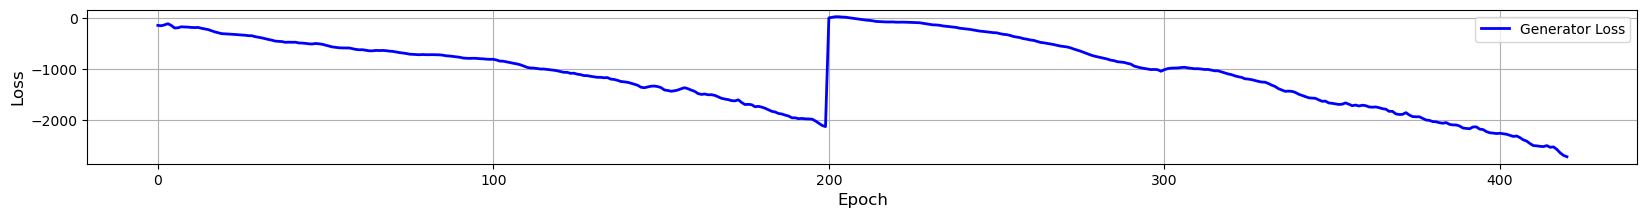

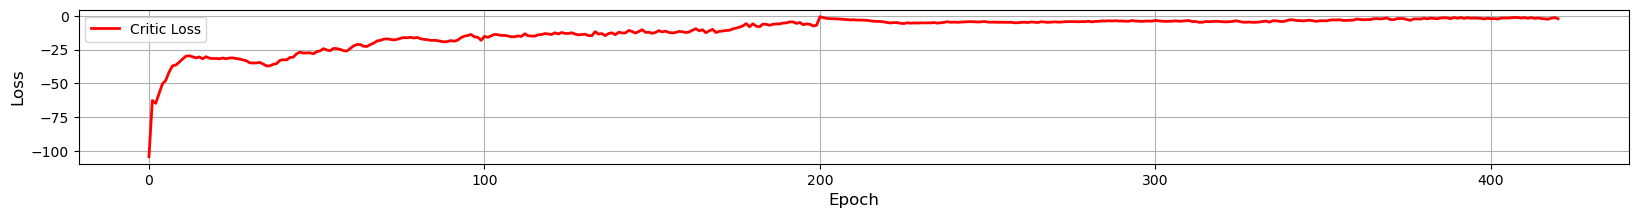

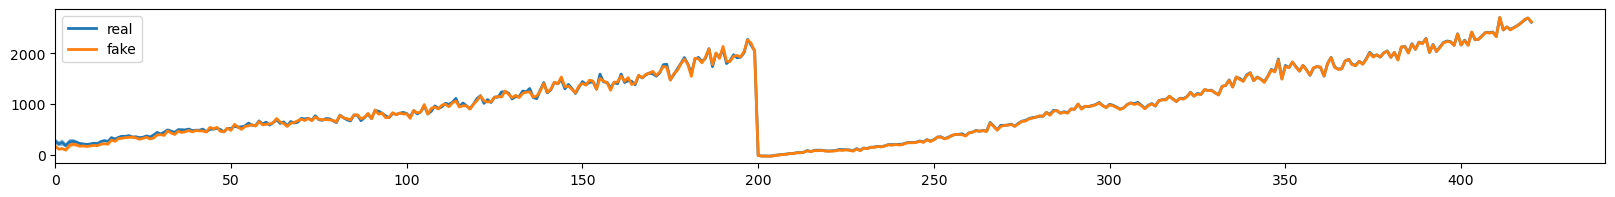

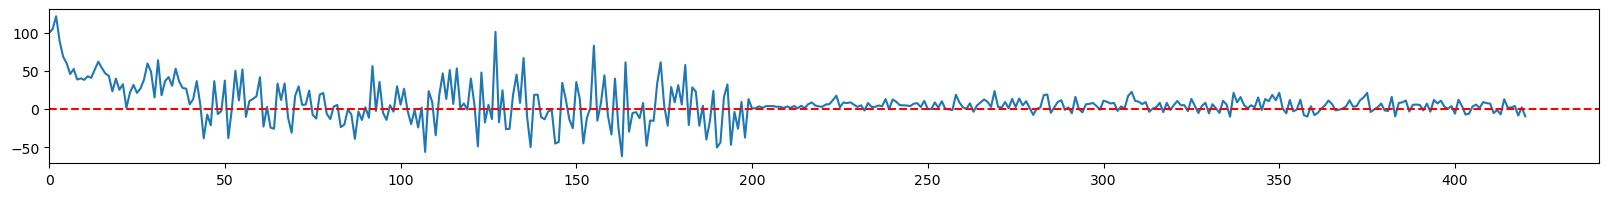

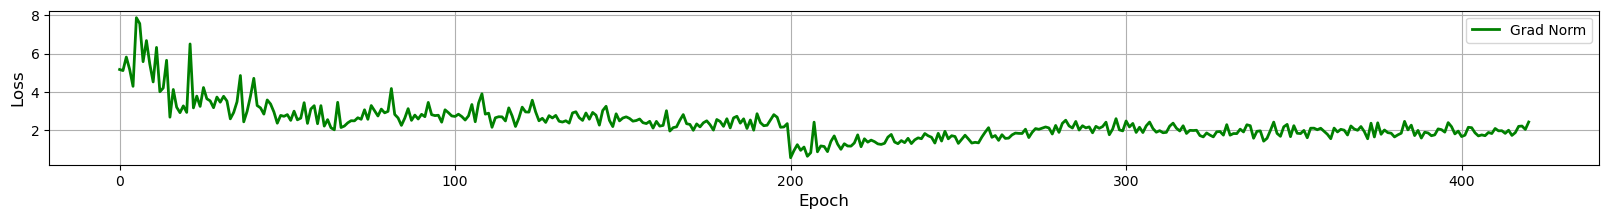

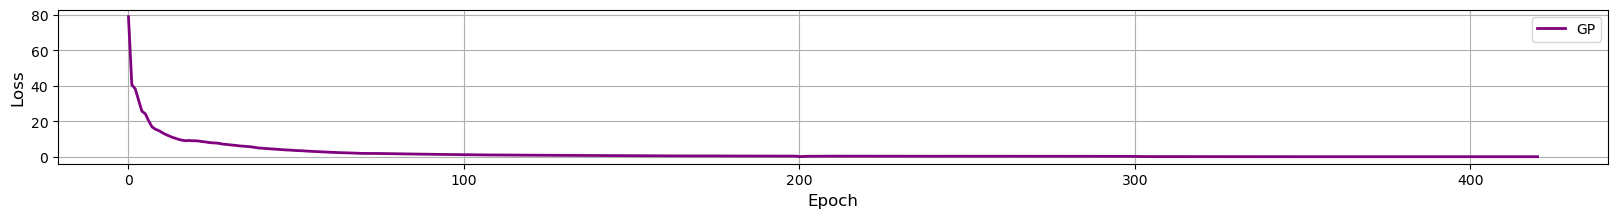

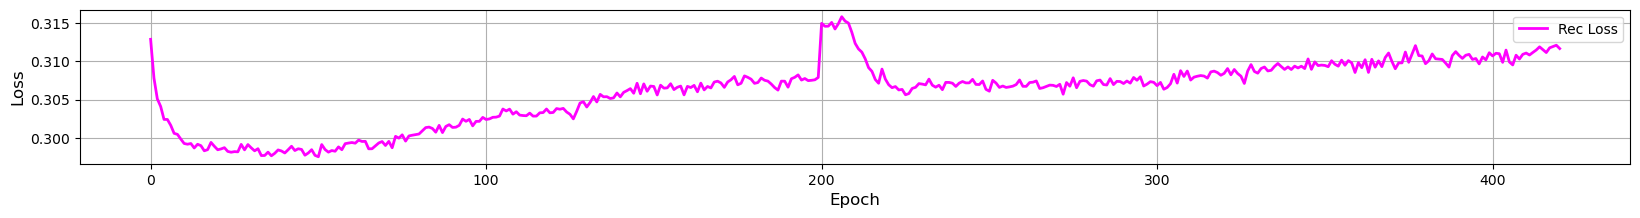

In [4]:
## Stats
import matplotlib.pyplot as plt
import pandas as pd
MODEL_ID = '20260330'
EPOCH = 200
STATS_PATH = f'logs/eo/{MODEL_ID}.csv'

def plot_loss(data, label, color='red'):
    plt.plot(data, label=label, color=color, linestyle='-', linewidth=2)
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.grid(True)
    plt.legend()


ep = None
bounded = (0, ep)
stats = pd.read_csv(STATS_PATH, index_col=0).reset_index()
plt.figure(figsize=(20, 2))
plot_loss(stats.loc[bounded[0]:bounded[1], '2 g_loss'], label='Generator Loss', color='blue')
plt.figure(figsize=(20, 2))
plot_loss(stats.loc[bounded[0]:bounded[1], '1 d_loss'], label='Critic Loss', color='red')

plt.figure(figsize=(20, 2))
plt.plot(stats.loc[bounded[0]:bounded[1], '5 real_pred'], label='real', linewidth=2)
plt.fill_between(stats.index, stats['5 real_pred'] - stats['7 real_pred_std'], stats['5 real_pred'] + stats['7 real_pred_std'], alpha=0.5)
plt.plot(stats.loc[bounded[0]:bounded[1], '6 fake_pred'], label='fake', linewidth=2)
plt.fill_between(stats.index, stats['6 fake_pred'] - stats['8 fake_pred_std'], stats['6 fake_pred'] + stats['8 fake_pred_std'], alpha=0.5)
plt.legend()
plt.xlim(bounded[0], bounded[1])
limmin = stats.loc[bounded[0]:bounded[1], '6 fake_pred'].min()
limmax = stats.loc[bounded[0]:bounded[1], '6 fake_pred'].max()
# plt.ylim(limmin, limmax)

plt.figure(figsize=(20, 2))
plt.plot(stats['5 real_pred'] - stats['6 fake_pred'])
plt.xlim(bounded[0], bounded[1])
plt.axhline(0, color='red', linestyle='--')
# plt.ylim(-30, 30)

plt.figure(figsize=(20, 2))
plot_loss(stats.loc[:ep, '3 critic_grad_norm'], label='Grad Norm', color='green')
plt.figure(figsize=(20, 2))
plot_loss(stats.loc[:ep, '4 gp'], label='GP', color='purple')

plt.figure(figsize=(20, 2))
plot_loss(stats.loc[:ep, '4b recon_loss'], label='Rec Loss', color='magenta') # 4b recon_loss

# plt.figure(figsize=(20, 2))
# plot_loss(stats.loc[:ep, '9 gen_grad_norm'], label='9 gen_grad_norm', color='orange') # 4b recon_loss

In [ ]:
# find at which epoch the recon_loss is minimum
stats['4b recon_loss'].idxmin(), stats['4b recon_loss'].min()

## Repetition check

In [5]:
appraoch = 2
def reverse_segmentation(x, n_subjects):
    return x.unflatten(0, (n_subjects, -1)).flatten(1, 2).permute(0, 2, 1)

if appraoch == 1:
    ## approach 1
    x_gen_reversed = reverse_segmentation(x_gen, N_SUBJECTS)
    blocks = x_gen_reversed.reshape(-1, 512, 8) 
    blocks = (blocks - blocks.mean(axis=(1,2), keepdims=True)) / blocks.std(axis=(1,2), keepdims=True)

    X = blocks.reshape(blocks.shape[0], -1)  #flatten
    corr_gen = np.corrcoef(X)

    # exclude diagonal
    iu = np.triu_indices_from(corr_gen, k=1)
    print(corr_gen[iu].mean())

elif appraoch == 2:
    x_gen_reversed = reverse_segmentation(x_gen, N_SUBJECTS)
    x_mean = x_gen_reversed.mean(0).permute(1, 0)

    # reshape into blocks of 512
    blocks = x_mean.reshape(-1, 512, x_mean.shape[-1])  # [n_blocks, 512, C]

    # compare blocks
    corr = np.corrcoef(blocks.reshape(blocks.shape[0], -1))
    iu = np.triu_indices_from(corr, k=1)
    print(corr[iu].mean())

0.33991030864958643


In [ ]:
import seaborn as sns

def sample_for_hist(x, n=15000, seed=0, keep_mean_exact=True):
    x = np.asarray(x).ravel()
    n = min(n, x.size)
    rng = np.random.default_rng(seed)
    y = x[rng.choice(x.size, size=n, replace=False)].astype(float)
    if keep_mean_exact:
        y += (x.mean() - y.mean())   # match original mean exactly
    return np.clip(y, -1, 1)         # correlations

X0 = sample_for_hist(corr_[iu], n=15000, seed=42)
X1 = sample_for_hist(corr_gen[iu], n=15000, seed=43)

plt.figure(figsize=(8,5))
sns.histplot(X0, bins=80, stat="density", kde=True, color="C0", alpha=0.35, label="corr_")
sns.histplot(X1, bins=80, stat="density", kde=True, color="C1", alpha=0.35, label="corr_gen")
plt.legend()
plt.show()

In [ ]:
fig, ax = plt.subplots(8, 1, figsize=(20, 16))
for i, ch in enumerate(range(len(CHANNELS))):
        plot_time_domain(reverse_segmentation(x, N_SUBJECTS), reverse_segmentation(x_gen, N_SUBJECTS), 4096, CHANNELS, ax[i], ch)

plt.legend()
plt.show()

## Intermediate layers

In [ ]:
@torch.no_grad()
def critic_feature_separation(critic, real_batch, fake_batch, sub_ids, state_ids, feature_dim, eps=1e-8):
    """
    real_batch: (B, T, C) or your input format for critic
    fake_batch: (B, T, C)
    sub_ids:    (B,) long/int
    state_ids:  (B,) long/int
    feature_dim: base C used in critic (the one you called feature_dim)
    Returns:
        per_dim: dict with delta and delta_norm tensors of shape (D_feat,)
        per_block: dict with block-wise scalars
    """

    # 1) Extract features
    # feats_r = critic.call({'x':real_batch, 'sub':sub_ids, 'pos':state_ids})  # (B, D_feat)
    # feats_f = critic.call({'x':fake_batch, 'sub':sub_ids, 'pos':state_ids})  # (B, D_feat)

    feats_r = critic.extract_features(real_batch, sub_ids, state_ids)  # (B, D_feat)
    feats_f = critic.extract_features(fake_batch, sub_ids, state_ids)  # (B, D_feat)

    # Ensure torch tensors
    if not isinstance(feats_r, torch.Tensor):
        feats_r = torch.as_tensor(feats_r)
    if not isinstance(feats_f, torch.Tensor):
        feats_f = torch.as_tensor(feats_f)

    # 2) Per-dimension delta
    delta = (feats_r - feats_f).abs().mean(dim=0)  # (D_feat,)

    # 3) Normalization by variability (per dim)
    std_r = feats_r.std(dim=0, unbiased=False)
    std_f = feats_f.std(dim=0, unbiased=False)
    delta_norm = delta / (std_r + std_f + eps)

    # 4) Block slicing
    C1 = feature_dim
    C2 = 2 * feature_dim
    C3 = 8 * feature_dim
    C4 = 16 * feature_dim

    idx1 = slice(0, C1)
    idx2 = slice(C1, C1 + C2)
    idx3 = slice(C1 + C2, C1 + C2 + C3)
    # idx4 = slice(C1 + C2 + C3, C1 + C2 + C3 + C4)
    # idx5 = slice(C1 + C2 + C3 + C4, -1)

    def block_stats(x, sl):
        return x[sl].mean().item()

    per_block = {
        "h1_delta":      block_stats(delta, idx1),
        "h2_delta":      block_stats(delta, idx2),
        "h3_delta":      block_stats(delta, idx3),
        # "h4_delta":      block_stats(delta, idx4),
        # "h5_delta":      block_stats(delta, idx5),
        "h1_delta_norm": block_stats(delta_norm, idx1),
        "h2_delta_norm": block_stats(delta_norm, idx2),
        "h3_delta_norm": block_stats(delta_norm, idx3),
        # "h4_delta_norm": block_stats(delta_norm, idx4),
        # "h4_delta_norm": block_stats(delta_norm, idx5),
    }

    per_dim = {"delta": delta, "delta_norm": delta_norm}
    return per_dim, per_block, delta, feats_r


In [ ]:
b = 1200
critic = model.critic
per_dim, per_block, delta, f_r = critic_feature_separation(
    critic=critic,
    real_batch=x[:b].float().to('mps'),
    fake_batch=x_gen[:b].float().to('mps'),
    sub_ids=sub[:b].to('mps'),
    state_ids=state[:b].to('mps'),
    feature_dim=8,
)

print(per_block)

In [ ]:
critic = model.critic
critic.eval()
critic.output_features = True

out = critic.predict({'x':x[:128+32], 'sub':sub[:128+32], 'pos':state[:128+32]})
plt.plot(out.std(0))

plt.figure(figsize=(20, 2))
plt.plot(out[00, :300])
plt.plot(out[20, :300])
plt.plot(out[30, :300])

In [ ]:
critic = model.critic
bs = 1200
with torch.no_grad():
    critic.output_features = True
    z = critic.predict({'x': x[:bs], 'sub': sub[:bs], 'pos': state[:bs]})  # (B, D)
    critic.output_features = False

    var = torch.tensor(z.var(axis=0))           # (D,)
    topk = torch.topk(var, k=50).values
    print("median var:", var.median().item(), "top-50 mean var:", topk.mean().item())

In [ ]:
u, s, v = torch.pca_lowrank(torch.tensor(z), q=20)
print("top singular values:", s)

In [ ]:
from keras import ops, layers
inputs = keras.Input(shape=(512, 8))
# sub_emb = critic.layers[0](sub.view(-1))
# sub_emb = critic.layers[1](x, sub_emb)
x_hp = critic.layers[3](inputs)
x_cat = ops.concatenate([inputs, x_hp], axis=-1)
h1 = critic.layers[4](x_cat)
h = layers.Flatten()(h1)
# out = ops.concatenate([h, h1], axis=-1)

# sub_emb = critic.layers[0](sub[128:128+32].to('mps').view(-1))
# state_emb = critic.layers[1](state_ids[128:128+32].to('mps'))
# x_ = critic.layers[3](x[128:128+32].float().to('mps'), sub_emb)

extractor = keras.Model(inputs, h)
out = extractor.predict(x[128:128+32].float().to('mps'))
plt.plot(out.std(0))

plt.figure(figsize=(20, 2))
plt.plot(out[00, :300])
plt.plot(out[20, :300])
plt.plot(out[30, :300])

### Critic Real vs. Fake Speratability

In [ ]:
# from src.EEGModalNet.models.FiLMGAN import FiLMGAN
# CHECKPOINTS_PATH = 'logs/eo/20260224_vepoch_160.model.keras'
# model = keras.saving.load_model(CHECKPOINTS_PATH, custom_objects={'FiLMGAN': FiLMGAN}, compile=False)
# with torch.no_grad():
#      x_gen = generate_data(model, x, sub, state, N_SUBJECTS, latent_dim=LATENT_DIM, use_random_sub=False).cpu()

rndidx = torch.randperm(x[:bs].shape[0])
critic = model.critic
critic.eval()
critic.output_features = True

z_real = torch.tensor(critic.predict({'x': x[:bs].float().to('mps'),
                    'sub': sub[:bs].to('mps'),
                    'pos': state[:bs].to('mps')}))
z_fake = torch.tensor(critic.predict({'x': x_gen[:bs].float().to('mps'),
                    'sub': sub[:bs][rndidx].to('mps'),
                    'pos': state[:bs][rndidx].to('mps')}))

dist = (z_real.mean(0) - z_fake.mean(0)).norm().item()
print("ciritc separability:", dist / ((z_real.norm(dim=1).mean().item() + z_fake.norm(dim=1).mean().item()) / 2) * 100)

### Correlation between intermediate layers and the output 

In [ ]:
# critic = model.critic
# critic.eval()
# critic.trainable = False
# critic.output_features = False

# with torch.no_grad():
#     out, z = critic({'x': x.float().to('mps'),
#                      'sub': sub.to('mps'),
#                      'pos': state.to('mps')})

#     zn = z.norm(dim=1)
#     zn_centered = zn - zn.mean()
#     out_centered = out - out.mean()

#     corr = (zn_centered * out_centered).mean() / (
#     zn_centered.std() * out_centered.std() + 1e-8
#     )

#     # corr = torch.corrcoef(torch.stack([zn, out.squeeze()]))[0,1].item()

#     print("corr(||feat||, out):", corr)

## Quality of the Generated Data

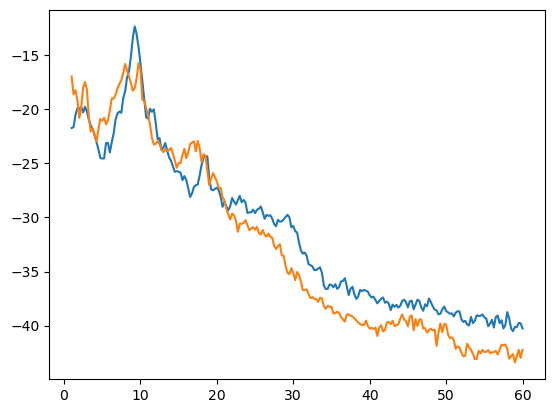

In [7]:
# x_gen_reversed.shape
x_reversed = reverse_segmentation(x, N_SUBJECTS).cpu().detach()
s = 2

psd, freqs = mne.time_frequency.psd_array_welch(x_gen_reversed[s].numpy(), sfreq=128, fmin=1, fmax=60, n_fft=512, verbose=False)
psd_real, freqs = mne.time_frequency.psd_array_welch(x_reversed[s].numpy(), sfreq=128, fmin=1, fmax=60, n_fft=512, verbose=False)
psd = 10*np.log10(psd)
psd_real = 10*np.log10(psd_real)

ch = 0
plt.plot(freqs, psd[ch])
plt.plot(freqs, psd_real[ch])

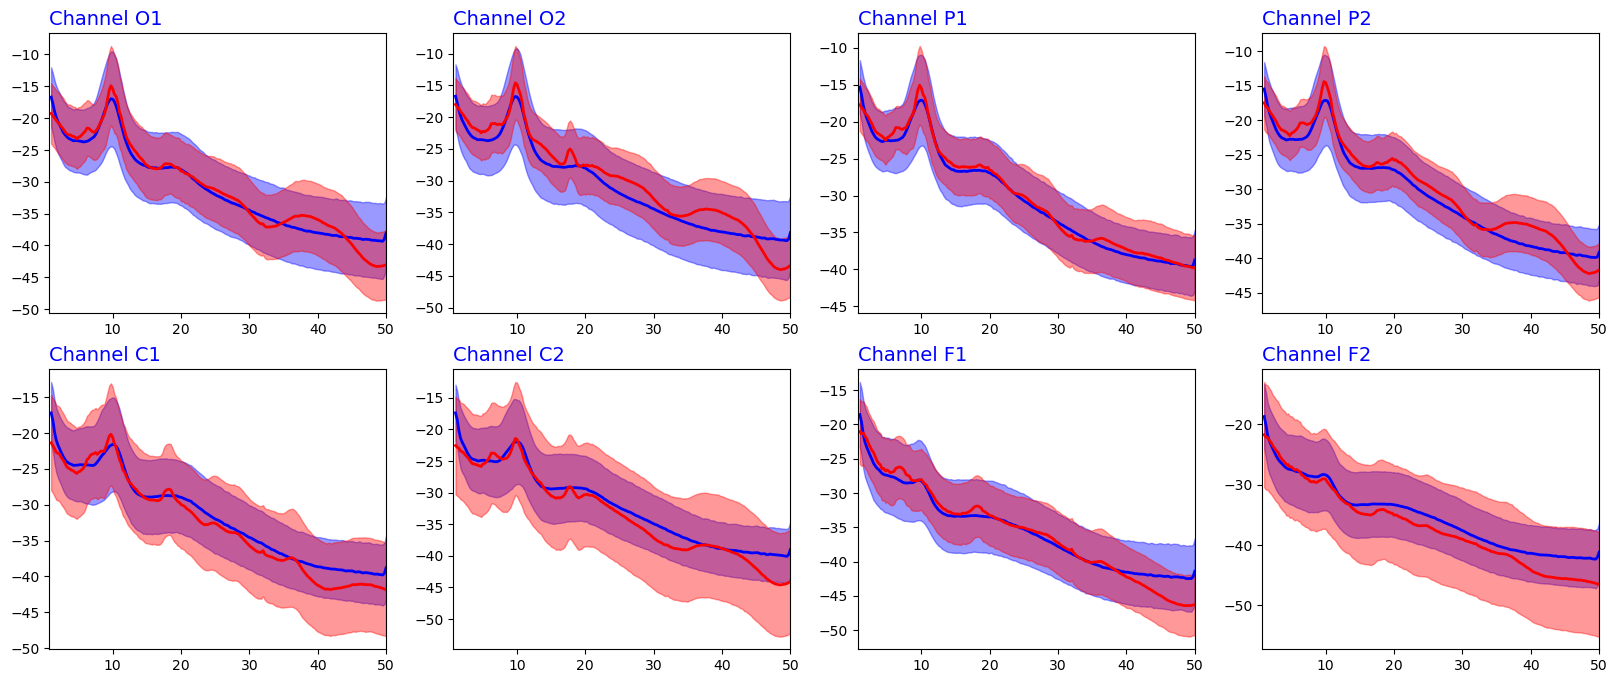

In [ ]:
_, ax = plt.subplots(2, 4, figsize=(20, 8))
plot_psd_multi_channel(x, CHANNELS, ax, n_subjects=N_SUBJECTS, reverse_first=True)
plot_psd_multi_channel(x_gen, CHANNELS, ax, n_subjects=N_SUBJECTS, reverse_first=True, color='red')

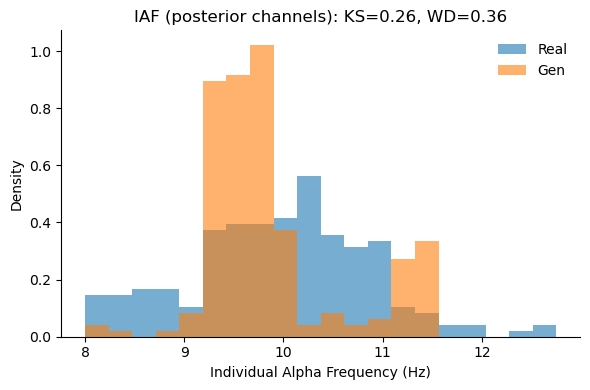

Real IAF: median=10.00 Hz, IQR=(9.25, 10.50)
Gen  IAF: median=9.75 Hz, IQR=(9.31, 10.00)
KS=0.262, WD=0.364


In [ ]:
psd_real, psd_fake, freqs = calculate_psd_different_methods(x, x_gen, N_SUBJECTS, psd_method='reverse_first')
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

iaf_r, iaf_g = iaf_analysis(psd_real, psd_fake, freqs, posterior_ch_idx=(0, 1, 2, 3))

## Compre Epochs

>>>>>> 200


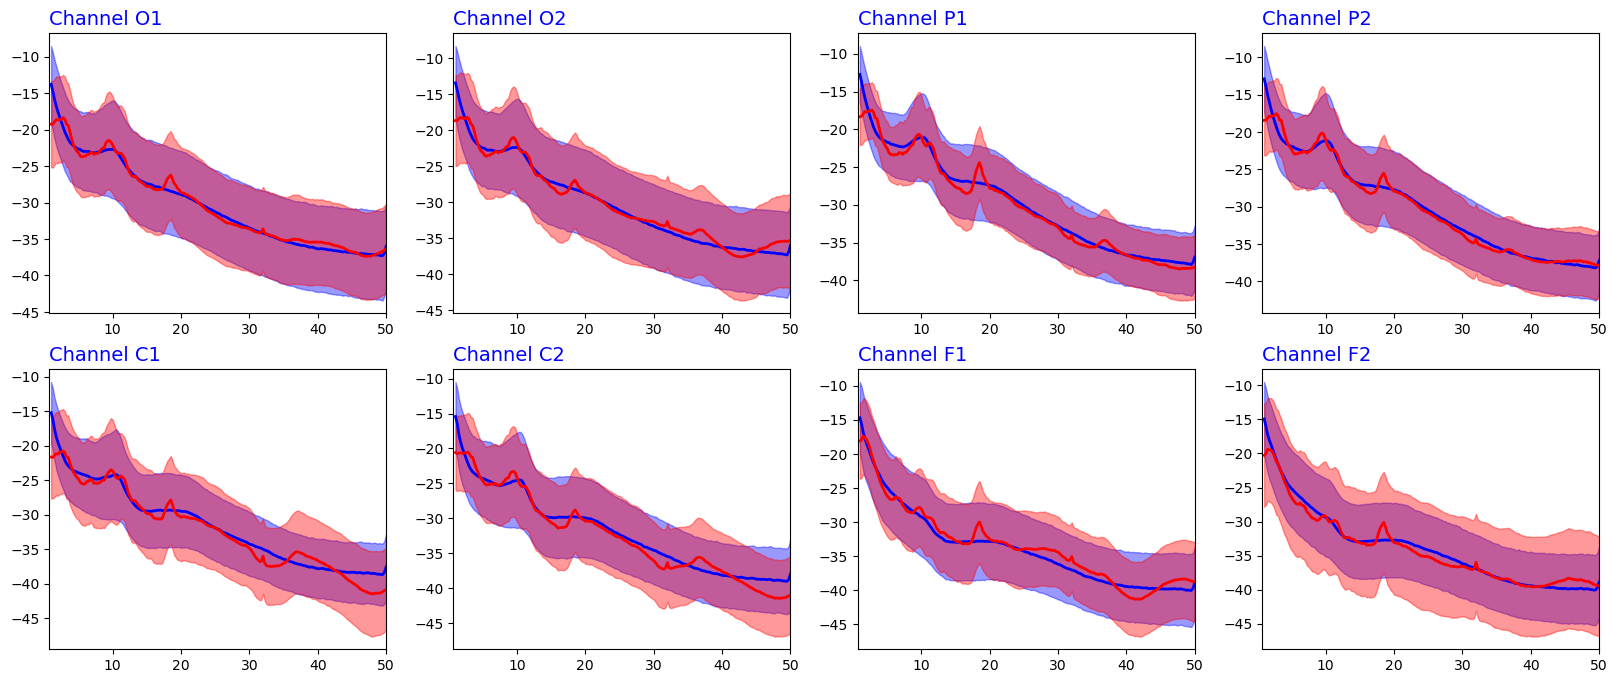

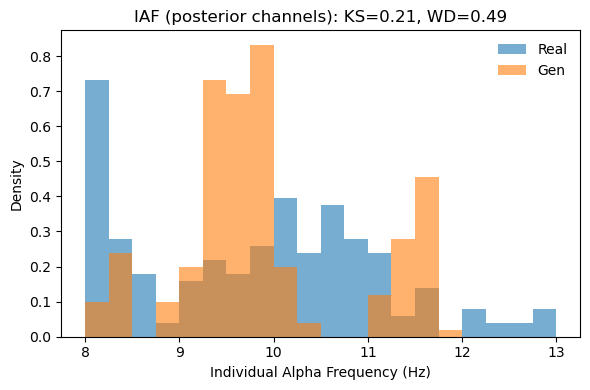

Real IAF: median=9.75 Hz, IQR=(8.31, 10.50)
Gen  IAF: median=9.50 Hz, IQR=(9.25, 10.00)
KS=0.213, WD=0.485
>>>>>> 210


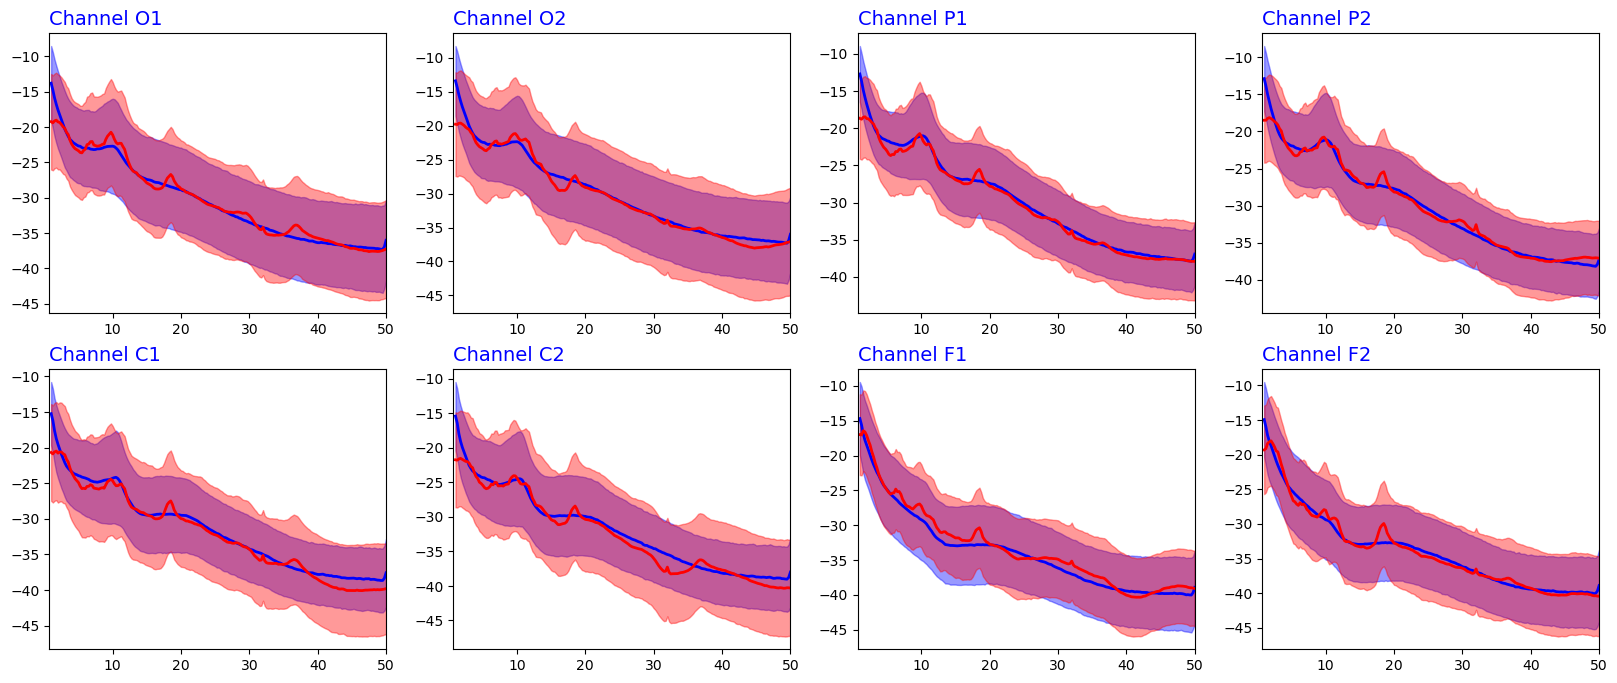

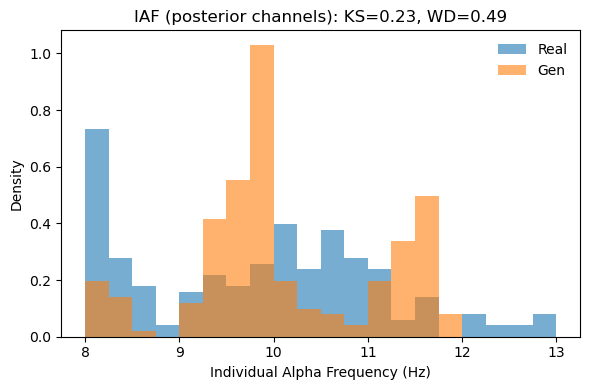

Real IAF: median=9.75 Hz, IQR=(8.31, 10.50)
Gen  IAF: median=9.75 Hz, IQR=(9.50, 11.00)
KS=0.228, WD=0.486
>>>>>> 220


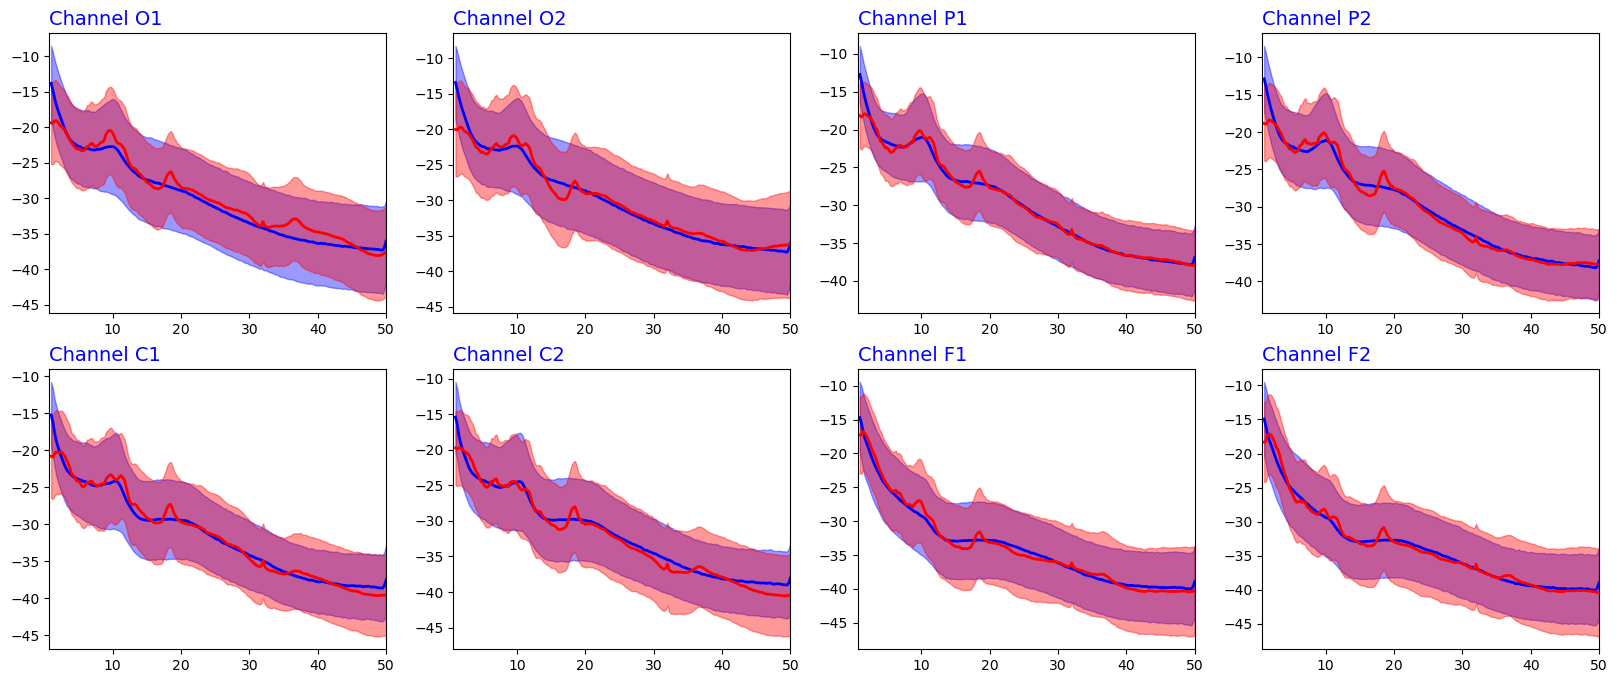

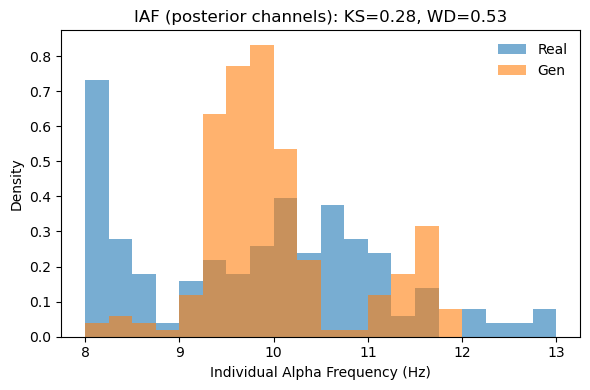

Real IAF: median=9.75 Hz, IQR=(8.31, 10.50)
Gen  IAF: median=9.75 Hz, IQR=(9.50, 10.00)
KS=0.277, WD=0.535
>>>>>> 230


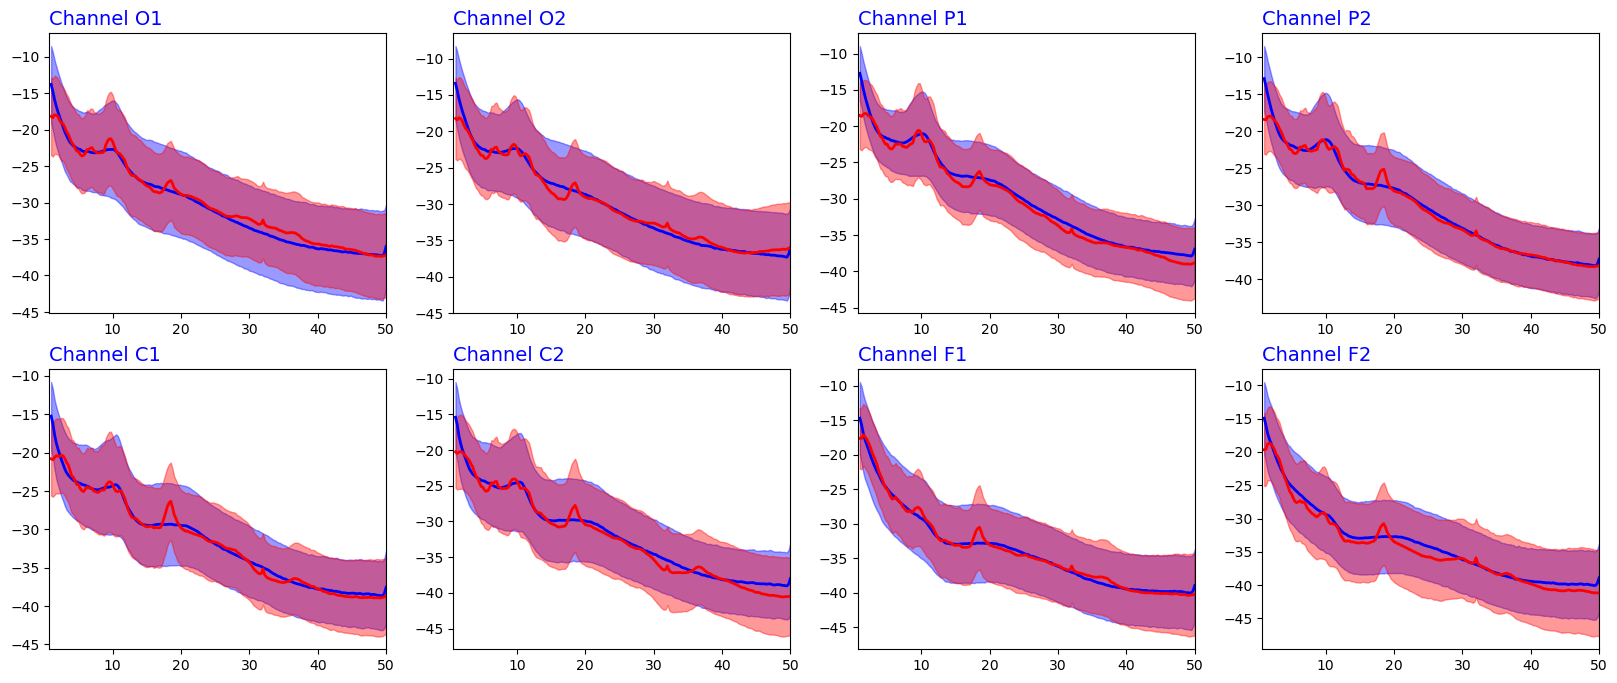

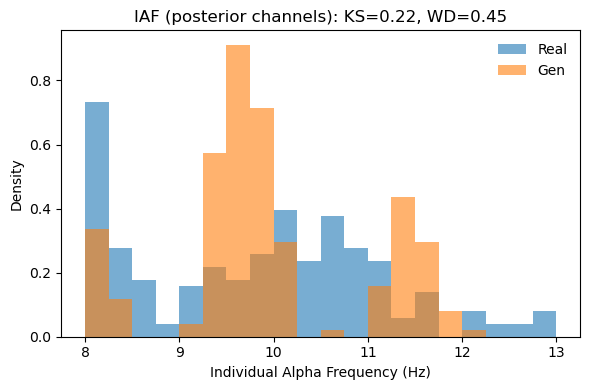

Real IAF: median=9.75 Hz, IQR=(8.31, 10.50)
Gen  IAF: median=9.75 Hz, IQR=(9.25, 10.38)
KS=0.223, WD=0.448
>>>>>> 240


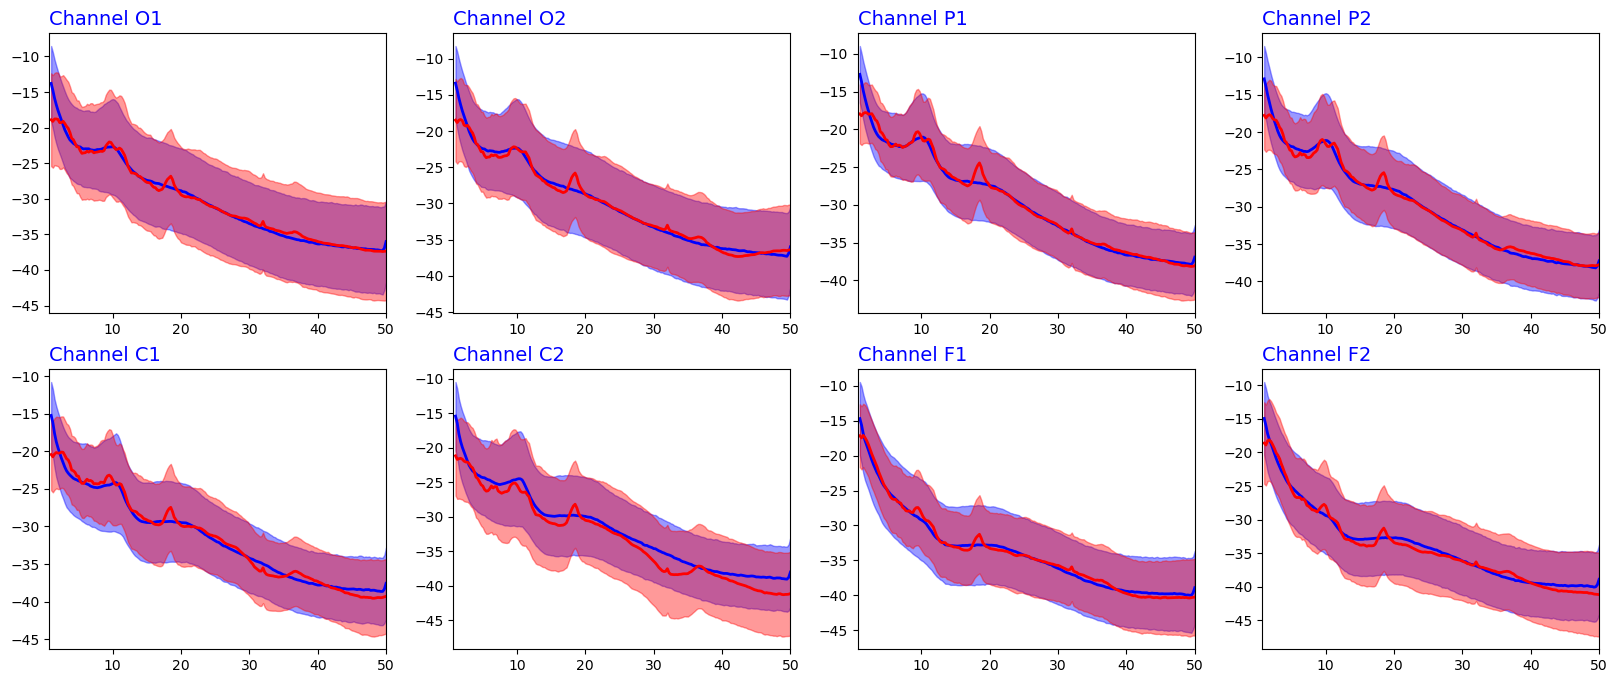

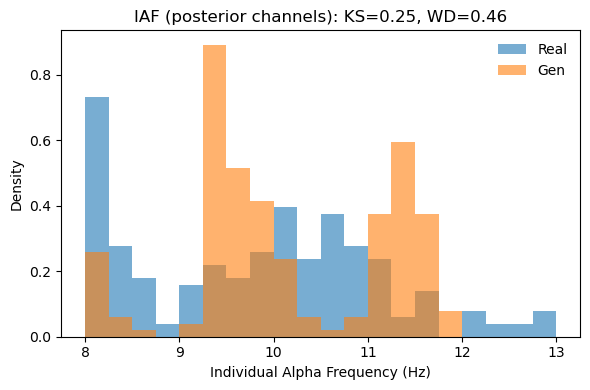

Real IAF: median=9.75 Hz, IQR=(8.31, 10.50)
Gen  IAF: median=9.75 Hz, IQR=(9.25, 11.25)
KS=0.252, WD=0.463
>>>>>> 250


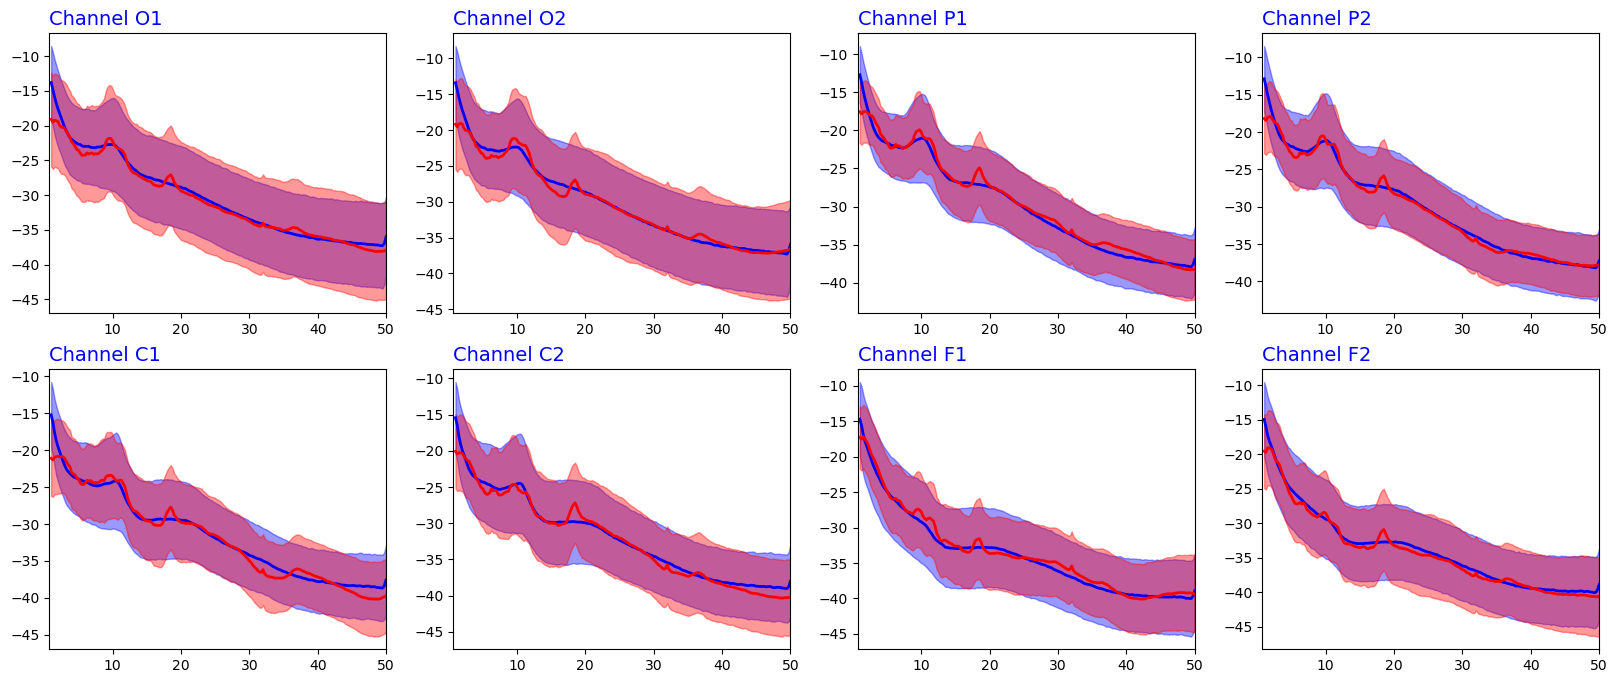

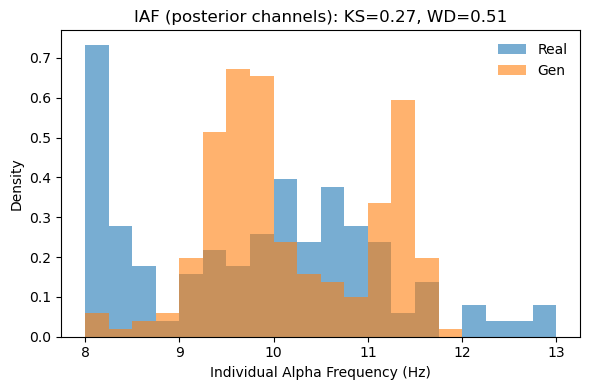

Real IAF: median=9.75 Hz, IQR=(8.31, 10.50)
Gen  IAF: median=9.75 Hz, IQR=(9.50, 11.00)
KS=0.267, WD=0.507
>>>>>> 260


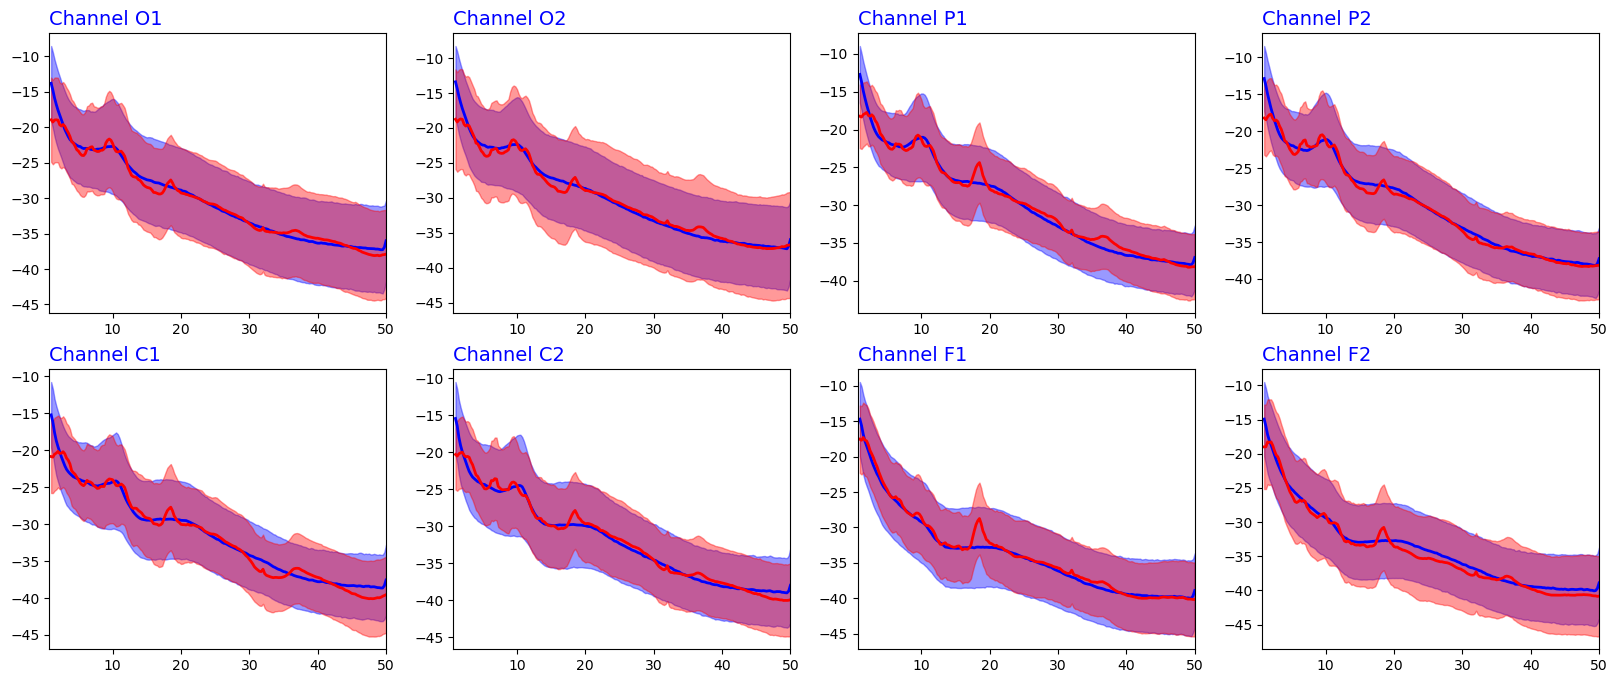

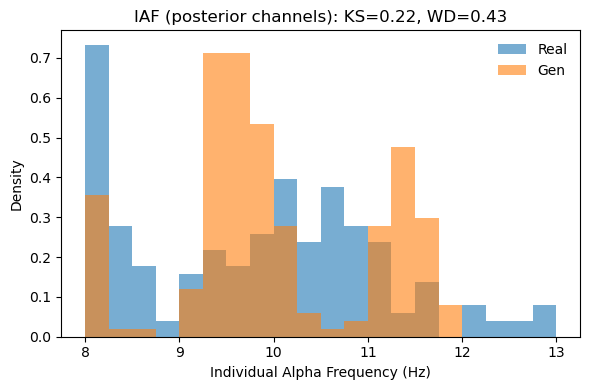

Real IAF: median=9.75 Hz, IQR=(8.31, 10.50)
Gen  IAF: median=9.75 Hz, IQR=(9.25, 11.00)
KS=0.218, WD=0.428
>>>>>> 270


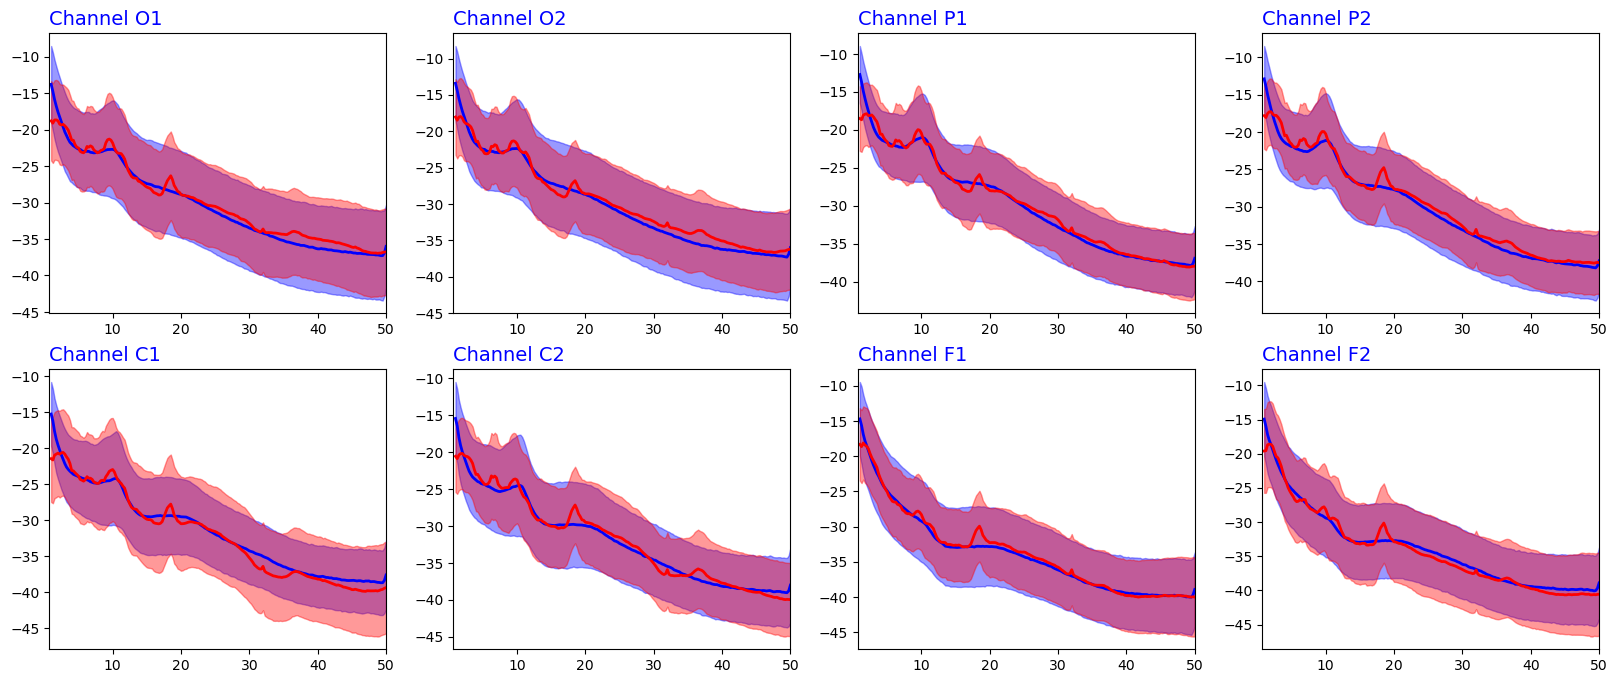

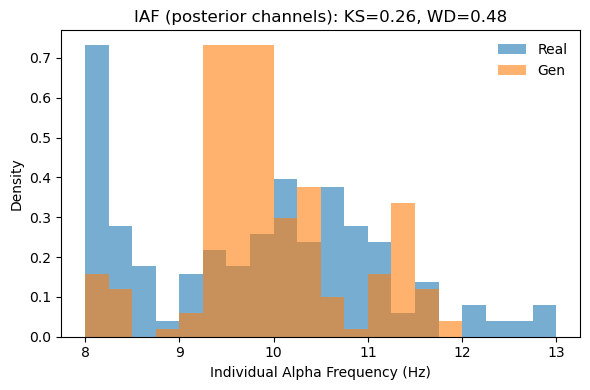

Real IAF: median=9.75 Hz, IQR=(8.31, 10.50)
Gen  IAF: median=9.75 Hz, IQR=(9.25, 10.25)
KS=0.257, WD=0.479
>>>>>> 280


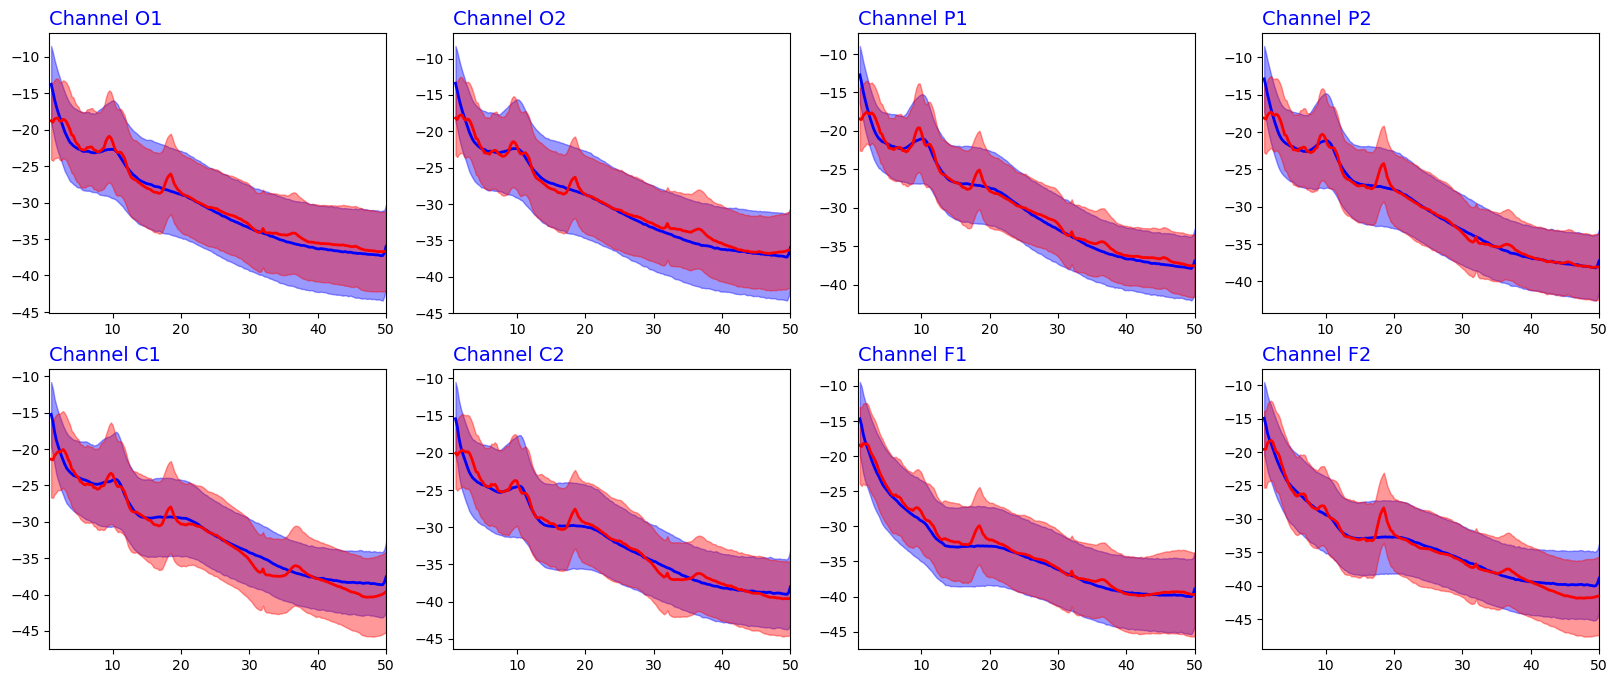

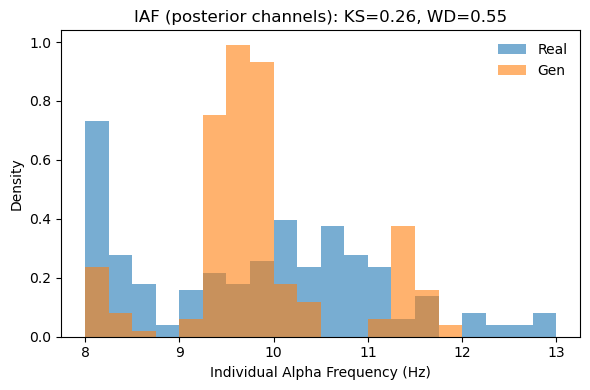

Real IAF: median=9.75 Hz, IQR=(8.31, 10.50)
Gen  IAF: median=9.50 Hz, IQR=(9.25, 9.75)
KS=0.257, WD=0.551
>>>>>> 290


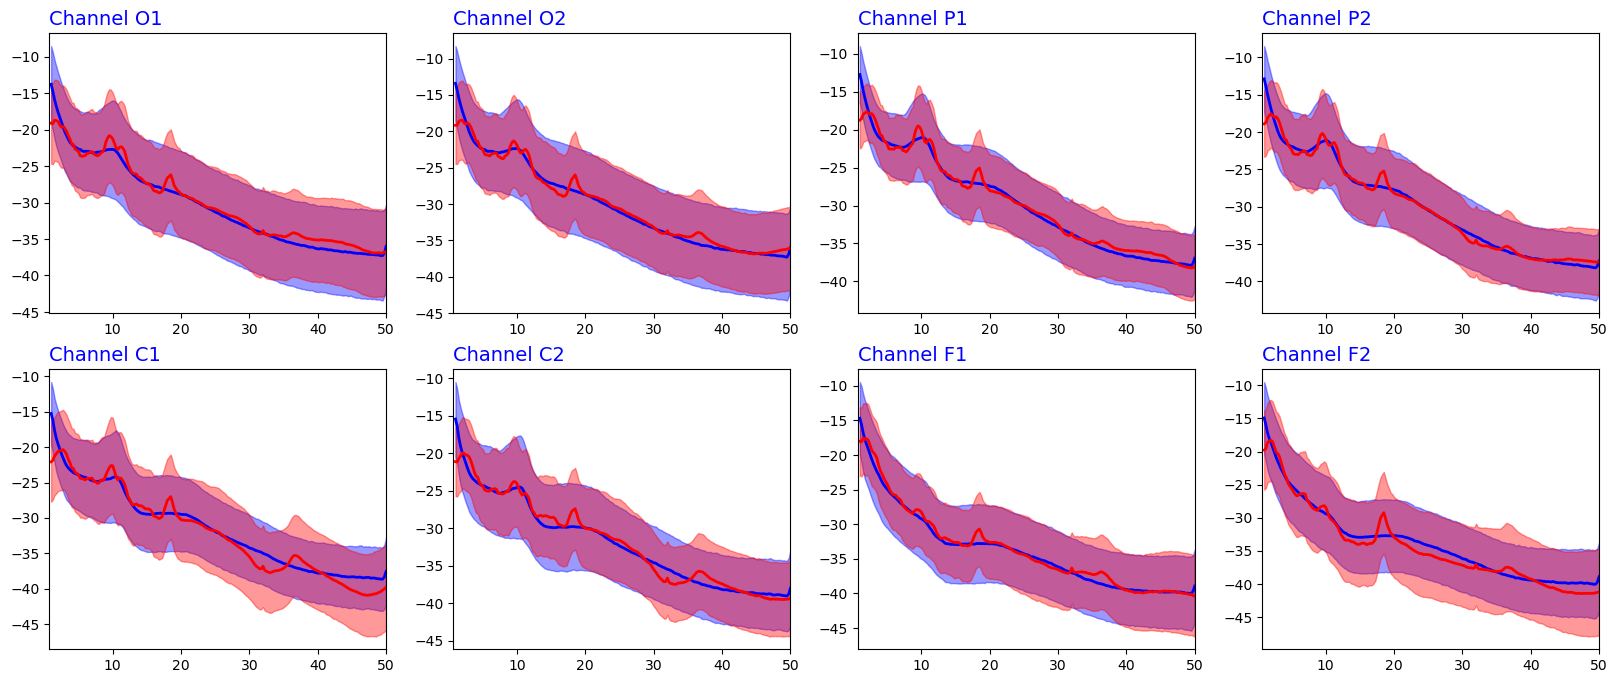

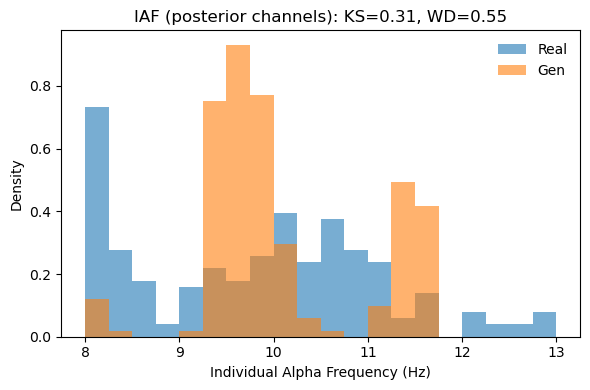

Real IAF: median=9.75 Hz, IQR=(8.31, 10.50)
Gen  IAF: median=9.75 Hz, IQR=(9.50, 10.88)
KS=0.307, WD=0.548


In [21]:
for ep in range(200, 300, 10):
    print(f'>>>>>> {ep}')
    CHECKPOINTS_PATH = f'logs/eo/20260330/20260330_epoch_{ep}.model.keras'
    model = keras.saving.load_model(CHECKPOINTS_PATH, custom_objects={'FiLMGAN': FiLMGAN}, compile=False)

    with torch.no_grad():
        x_gen = generate_data(model, x, sub, state, N_SUBJECTS, latent_dim=LATENT_DIM, use_random_sub=False).cpu()

    _, ax = plt.subplots(2, 4, figsize=(20, 8))
    psd_real, freqs = plot_psd_multi_channel(x, CHANNELS, ax, n_subjects=N_SUBJECTS, reverse_first=True, return_psds=True)
    psd_fake, freqs = plot_psd_multi_channel(x_gen, CHANNELS, ax, n_subjects=N_SUBJECTS, reverse_first=True, color='red', return_psds=True)

    # psd_real, psd_fake, freqs = calculate_psd_different_methods(x, x_gen, N_SUBJECTS, psd_method='reverse_first')
    iaf_r, iaf_g = iaf_analysis(psd_real, psd_fake, freqs, posterior_ch_idx=(0, 1, 2, 3))

## Critic Performance

In [ ]:
critic = model.critic

rndidx = torch.randperm(x.shape[0])

with torch.no_grad():
    real_pred = critic.predict(data)
    fake_pred = critic.predict({'x': x_gen.float().to('mps'), 'sub': sub[rndidx].to('mps'), 'pos': state[rndidx].to('mps')})

In [ ]:
fake_scores = fake_pred[0].flatten()
real_scores = real_pred[0].flatten()
import seaborn as sns

sns.histplot(real_scores, bins=20, alpha=0.5, label='real', kde=True)
sns.histplot(fake_scores, bins=20, alpha=0.5, label='fake', kde=True)
plt.legend()
plt.title(f'Epoch {EPOCH}')
plt.show()

# plot a normal distribution using the mean and std and min and max values of the critic scores
f_scores = np.random.normal(fake_scores.mean(), fake_scores.std(), 1000)
r_scores = np.random.normal(real_scores.mean(), real_scores.std(), 1000)

# Clip the generated scores to the min and max values of the real and fake scores
r_scores = np.clip(r_scores, real_scores.min(), real_scores.max())
f_scores = np.clip(f_scores, fake_scores.min(), fake_scores.max())

sns.histplot(r_scores, label='real', kde=True)
sns.histplot(f_scores, label='fake', kde=True)
plt.legend()

# Train a classifier on the real and generated features

In [ ]:
from sklearn.metrics import roc_auc_score
critic = model.critic
critic.eval()
critic.output_features = True
bs = 1200

z_real = torch.tensor(critic.predict({'x': x[:bs].float().to('mps'), 'sub': sub[:bs].to('mps'), 'pos': state[:bs].to('mps')}))
z_fake = torch.tensor(critic.predict({'x': x_gen[:bs].float().to('mps'), 'sub': sub[:bs].to('mps'), 'pos': state[:bs].to('mps')}))

X = torch.cat([z_real, z_fake], dim=0)        # (2B, 12352)
y = torch.cat([
    torch.ones(z_real.size(0)),
    torch.zeros(z_fake.size(0))
], dim=0)

# break old graph
X = X.float().cpu().detach()
y = y.float().cpu().detach()

perm = torch.randperm(X.size(0), device=X.device)
X = X[perm]
y = y[perm]

split = int(0.8 * X.size(0))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

X_train = (X_train - X_train.mean()) / X_train.std()
X_test = (X_test - X_test.mean()) / X_test.std()  # use train stats for test normalization

clf = torch.nn.Linear(X.shape[1], 1).to(X.device)
optimizer = torch.optim.Adam(clf.parameters(), lr=1e-3)
loss_fn = torch.nn.BCEWithLogitsLoss()

for _ in range(200):
    logits = clf(X_train).squeeze(-1)
    loss = loss_fn(logits, y_train.float())  # BCE expects float targets
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()


with torch.no_grad():
    logits = clf(X_test).squeeze()
    probs = torch.sigmoid(logits)
    auc = roc_auc_score(y_test.numpy(), probs.numpy())

print("C2ST AUC test:", auc)

with torch.no_grad():
    logits = clf(X_train).squeeze()
    probs = torch.sigmoid(logits)
    auc = roc_auc_score(y_train.numpy(), probs.numpy())
print("C2ST AUC train:", auc)

# CLASSIFICATION

## setup

In [3]:
## Classification
from typing import List
from keras.layers import MaxPooling1D, Flatten, Concatenate
from keras import Model, layers
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, train_test_split 
from src.EEGModalNet.preprocessing.preprocessing import preprocess_data
from sklearn.preprocessing import StandardScaler
import torch.nn.functional as F
from src.EEGModalNet.utils.extractor import extract_features_batched_deterministic, fit_new_subject_embeddings

# Constants
EEG_DATA_PATH = 'data/LEMON_DATA/EO-EC_processed_ch-16_sf-128.nc5'
DEMOGRAPHICS_PATH = 'logs/age_group_classifier/Demographics.csv'
CLS_CHECKPOINT_PATH = 'logs/'


def plot_some_features(out):
    plt.figure(figsize=(20, 2))

    if out.ndim == 3:
        plt.plot(out[000, :, 0])
        plt.plot(out[100, :, 0])
        plt.plot(out[150, :, 0])
    else:
        plt.plot(out[000, :100])
        plt.plot(out[100, :100])
        plt.plot(out[150, :100])

## otka data

In [44]:
TASK = 'hypno' # gender, age, hypno, hypno_depth
DO_DOWN_SAMPLE = True
DATA_TO_BE_USED = 'OTKA'
REORDERING = False
PREPROCESSING = True

if DATA_TO_BE_USED == 'OTKA' and TASK != 'hypno_depth':
    ## Train classifier on OTKA dataset
    # eeg data is experience data that is downsampled to 128Hz and Robustly scaled
    EEG = xr.open_dataarray('data/OTKA/experiment_EEG_data.nc5', engine='h5netcdf')
    # exclude_sub_ids = 'sub-52'
    # EEG = EEG.sel(subject=~EEG.subject.isin(exclude_sub_ids))
    behavioral = pd.read_csv('data/OTKA/PLB_HYP_data_MASTER.csv')
    if TASK == 'gender':
        classes = behavioral[['gender', 'bids_id']].dropna().set_index('bids_id')
        classes['gender'] = classes['gender'].apply(lambda x: 0 if x == 'Male' else 1)
        # classes = classes.query('bids_id != 52')
    elif TASK == 'hypno':
        classes = behavioral[['hypnotizability_total', 'bids_id']].dropna().set_index('bids_id')
        classes['hypnotizability_total'] = classes['hypnotizability_total'].apply(lambda x: 1 if x > 5 else 0)

    def format_subject_id(subject_id):
        return f"sub-{int(subject_id):02d}"

    sub_ids = classes.index
    if DO_DOWN_SAMPLE:
        n_y0 = (classes == 0).sum().values
        n_y1 = (classes == 1).sum().values
        n_min = min(n_y0, n_y1)
        n_subjects = n_min * 2
        if TASK == 'gender':
            y0_sub_ids = classes.query("gender == 0").index[:n_min[0]]
            y1_sub_ids = classes.query("gender == 1").index[:n_min[0]]
        if TASK == 'hypno':
            y0_sub_ids = classes.query("hypnotizability_total == 0").index[:n_min[0]]
            y1_sub_ids = classes.query("hypnotizability_total == 1").index[:n_min[0]]
        sub_ids = y1_sub_ids.append(y0_sub_ids)

    sub_ids_formatted = [format_subject_id(sub_id) for sub_id in sub_ids]

    # X_input
    x = EEG.sel(subject=sub_ids_formatted, channel=CHANNELS).to_numpy()
    x = x.reshape(-1, *x.shape[2:])

    # remove those two missing recordings from the last participants if it's among the sub ids
    if 52 in sub_ids:
        x = np.concatenate([x[:-3], x[-1:]])

    # Process
    x = preprocess_data(x, sampling_rate=128)

    # Highpass filter
    sos = butter(4, 0.5, btype='high', fs=128, output='sos')
    x = sosfiltfilt(sos, x, axis=-1)

    # Remove the line noise
    x, _ = dss.dss_line(x.T, fline=50, sfreq=128, nremove=1)
    x = x.T

    X_input = torch.tensor(x.copy()).unfold(2, TIME_DIM, TIME_DIM).permute(0, 2, 3, 1).flatten(0, 1)

    # Classes
    n_subjects = len(sub_ids)
    y = classes.loc[sub_ids].values
    # if REORDERING:
    #     y = y[reordering_idx]
    y = y.repeat(416)  # X_input.shape[0] // n_subjects

    # Groups
    sub = torch.tensor(np.arange(0, n_subjects).repeat(416)[:, np.newaxis])
    groups = sub.squeeze().numpy()

    # remove extra data from those two missing sessions
    y = y[:-208]
    groups = groups[:-208]

    print(y.mean())

elif TASK == 'hypno_depth':
    print('Classifying Hypnosis Depth')
    EEG = xr.open_dataarray('data/OTKA/experiment_EEG_data.nc5', engine='h5netcdf')
    behavioral = pd.read_csv('data/OTKA/behavioral_data.csv')

    rows = behavioral.query('description == "hypnosis"').drop(205)

    idx = rows["bids_id"].to_numpy().astype(int)
    sub_ids = [f"sub-{b:02}" for b in idx]
    sub_ids = xr.DataArray(sub_ids, dims="sample")

    task_idx = xr.DataArray(
        "experience" + rows["session"].astype(str).to_numpy(),
        dims="sample",
    )

    X = EEG.sel(channel=CHANNELS).sel(subject=sub_ids, tasks=task_idx,)

    x = X.to_numpy()

    y = rows["score"].apply(lambda v: 0 if v <= 5 else 1).to_numpy()

    # Process
    x = preprocess_data(x, sampling_rate=128)

    # Highpass filter
    sos = butter(4, 0.5, btype='high', fs=128, output='sos')
    x = sosfiltfilt(sos, x, axis=-1)

    # Remove the line noise
    x, _ = dss.dss_line(x.T, fline=50, sfreq=128, nremove=1)
    x = x.T

    X_input = torch.tensor(x.copy()).unfold(2, TIME_DIM, TIME_DIM).permute(0, 2, 3, 1).flatten(0, 1)

    # Classes
    n_sessions = len(task_idx)

    y = rows["score"].apply(lambda v: 0 if v <= 5 else 1).to_numpy()
    n_segments = X_input.shape[0] // n_sessions
    y = y.repeat(n_segments)

    # # Groups
    sub = torch.tensor((idx-1).repeat(n_segments)[:, np.newaxis])
    groups = sub.squeeze().numpy()

else:
    print(f'using DS data and task is {TASK}')
    EEG = xr.open_dataarray('data/ds005385/ds005385.nc5', engine='h5netcdf')
    sampling_rate = 128
    demo = pd.read_csv('data/ds005385/demographic.csv')
    demo = demo.set_index('participant_id')

    REORDERING = False

    if TASK == 'gender':
        classes = demo['sex'].apply(lambda x: 0 if x == 'F' else 1)
    elif TASK == 'age':
        classes = demo['age_group'].apply(lambda x: 0 if x == 'young' else 1)

    sub_ids = classes.index  #TODO: this will rewrite the sub_id from above, should be fixed
    if DO_DOWN_SAMPLE:
        print('balancing the classes')
        n_y0 = (classes == 0).sum()
        n_y1 = (classes == 1).sum()
        n_min = int(min(n_y0, n_y1))
        n_subjects = n_min * 2
        y0_sub_ids = classes[classes == 0].index[:n_min]
        y1_sub_ids = classes[classes == 1].index[:n_min]
        sub_ids = y0_sub_ids.append(y1_sub_ids)


    # X_input
    x = EEG.sel(subject=sub_ids, channel=CHANNELS).to_numpy()

    if PREPROCESSING:
        # Process
        x = preprocess_data(x, sampling_rate=sampling_rate)

        # Highpass filter
        sos = butter(4, 0.5, btype='high', fs=sampling_rate, output='sos')
        x = sosfiltfilt(sos, x, axis=-1)

        # Remove the line noise
        x, _ = dss.dss_line(x.T, fline=50, sfreq=sampling_rate, nremove=1)
        x = x.T

    if REORDERING:
        reordering_idx = torch.randperm(x.shape[0])
        x = x[reordering_idx]

    X_input = torch.tensor(x.copy()).unfold(2, TIME_DIM, TIME_DIM).permute(0, 2, 3, 1).flatten(0, 1)

    # Classes
    n_subjects = len(sub_ids)
    y = classes.loc[sub_ids].values
    if REORDERING:
        y = y[reordering_idx]
    y = y.repeat(X_input.shape[0] / n_subjects)

    # Groups
    sub = torch.tensor(np.arange(0, n_subjects).repeat(X_input.shape[0] // n_subjects)[:, np.newaxis]) 
    groups = sub.squeeze().numpy()

>>>>Corrected Mean: -0.08666441064987322, Std: 1.2747822810614324, Max: 20.24247541755422, Min: -16.626952643822857
>>>>Scaled Mean: 0.01026081591308275, Std: 1.2720746800422538, Max: 73.96679952609648, Min: -77.82273427008246
>>>>Normalized Mean: 1.5678235594591763e-17, Std: 0.9999999999999999, Max: 20.932522772079867, Min: -17.66132210232329
>>>>Clamped Mean: -7.217907625172027e-07, Std: 0.999985235806584, Max: 20.0, Min: -17.66132210232329
Power of components removed by DSS: 0.11
0.5074626865671642


## Classifier

In [45]:
from src.EEGModalNet.utils.extractor import extract_features_batched_deterministic, fit_new_subject_embeddings

In [ ]:
device = "cpu"
FINETUNE_SUB_EMB = False

CHECKPOINTS_PATH = "logs/eo/20260330/20260330_epoch_100.model.keras"

model = keras.saving.load_model(
    CHECKPOINTS_PATH,
    custom_objects={"FiLMGAN": FiLMGAN},
    compile=False,
)
critic = model.critic
critic.eval()
critic.to(device)

for p in critic.parameters():
    p.requires_grad = False

# Force-build the Keras conv layers on the SAME device
dummy = {
    "x": torch.zeros((1, critic.time_dim, critic.feature_dim), dtype=torch.float32, device=device),
    "subj_emb": torch.zeros((1, critic.d_sub), dtype=torch.float32, device=device),
    "pos": torch.zeros((1, 1), dtype=torch.long, device=device),
}
with torch.no_grad():
    _ = critic.encode_features(dummy)

# Reload checkpoint weights after build
model.load_weights(CHECKPOINTS_PATH)

# Keep all feature inputs on the SAME device
e_mean = critic.sub_emb.module.weight.mean(0).detach().to(device)
B = X_input.shape[0]
subj_emb = e_mean[None, :].repeat(B, 1)
state_ids = torch.zeros((B, 1), dtype=torch.long, device=device)

if FINETUNE_SUB_EMB:
    new_sub_ids = torch.arange(0, len(sub_ids))
    E_new, unique_subjects = fit_new_subject_embeddings(critic,
        X_input,                 
        new_sub_ids,        
        state_ids,              
        e_mean,            
        batch_size=256,
        n_steps=500,
        max_segments_per_subject=408,
        lr=1e-2,
        reg_lambda=1e-3,
        device=device,
        clamp_norm=False)

    # map every segment's original subject ID to local ID
    id_to_local = {int(s.item()): i for i, s in enumerate(unique_subjects)}
    local_ids = torch.tensor(
        [id_to_local[int(s.item())] for s in new_sub_ids.view(-1).cpu()],
        dtype=torch.long,
    )

    # per-segment embedding
    subj_emb_all = E_new[local_ids]  # (N, 32)
    subj_emb = subj_emb_all.repeat(416, 1)[:-208]

feats, _, _ = extract_features_batched_deterministic(
    critic,
    X_input,
    subj_emb,
    state_ids)

Text(0.5, 0, 'Embedding Dim 3')

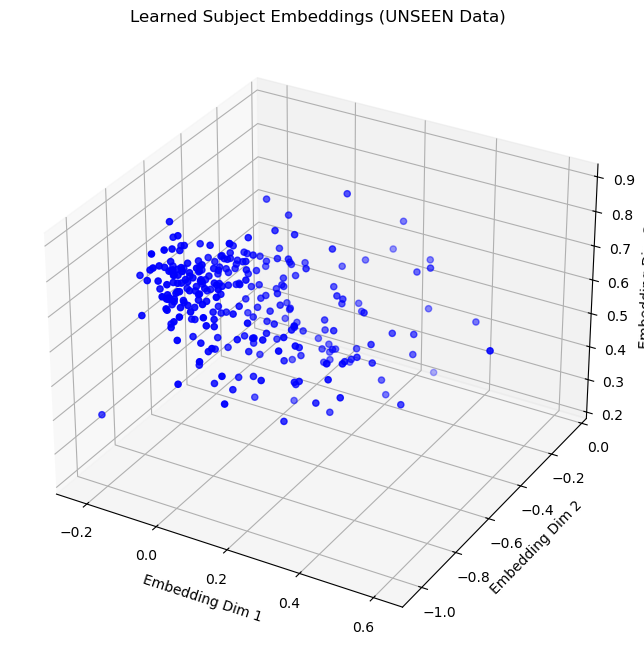

In [27]:
e_org = critic.sub_emb.module.weight.detach().cpu()

i = 20

to_be_plotted = E_new

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(to_be_plotted[:, i],
           to_be_plotted[:, i+1],
           to_be_plotted[:, i+2], label='Training Subjects', color='blue')
ax.set_title('Learned Subject Embeddings (UNSEEN Data)')
ax.set_xlabel('Embedding Dim 1')
ax.set_ylabel('Embedding Dim 2')
ax.set_zlabel('Embedding Dim 3')

In [17]:
E_train = critic.sub_emb.module.weight.detach().cpu()
e_mean = E_train.mean(0)

train_dist = torch.norm(E_train - e_mean[None, :], dim=1)

print("train dist mean:", train_dist.mean().item())
print("train dist median:", train_dist.median().item())
print("train dist 95%:", torch.quantile(train_dist, 0.95).item())

train dist mean: 5.513051986694336
train dist median: 5.27479362487793
train dist 95%: 7.953563690185547


0.4888888888888889 0.5454545454545454
Features mean 0.054206606 std: 0.104646504
Feature train mean: -0.0161156 std: 1.0900375
Feature val mean: 0.032963738 std: 0.78324014


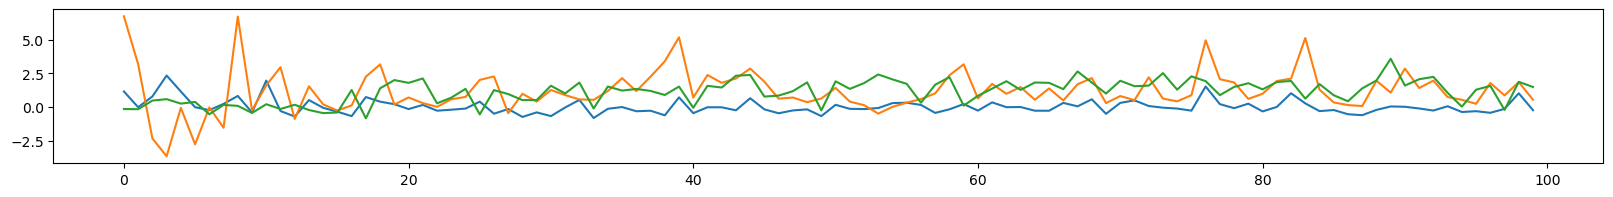

In [49]:
scale = True
split_method = 'group_shuffle' # 'stratified' or 'group_shuffle'
rnds = 19

if split_method == 'group_shuffle':
    group_shuffle = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=rnds)
    train_idx, val_idx = next(group_shuffle.split(X_input, y, groups=groups))
elif split_method == 'stratified':
    train_idx, val_idx = train_test_split(np.arange(X_input.shape[0]), test_size=0.3, random_state=rnds, stratify=y)
else:
    raise ValueError(f'Unknown split method: {split_method}')


print(y[train_idx].mean(), y[val_idx].mean())

if scale:
    scaler = StandardScaler().fit(feats)
    feats_train = scaler.transform(feats[train_idx])
    feats_val = scaler.transform(feats[val_idx])

else:
    feats_train = feats[train_idx]
    feats_val = feats[val_idx]

plot_some_features(feats_train)
print("Features mean", feats.mean(), "std:", feats.std()) 
print("Feature train mean:", feats_train.mean(), "std:", feats_train.std())
print("Feature val mean:", feats_val.mean(), "std:", feats_val.std())

In [43]:
cls_model = keras.models.Sequential([
    layers.Dense(1, activation='sigmoid')
])

cls_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.BinaryCrossentropy(from_logits=False),
    metrics=[
        keras.metrics.AUC(name="auc"),
        keras.metrics.BinaryAccuracy(threshold=0.5, name="accuracy")
    ]
    )

cw = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y[train_idx]),
    y=y[train_idx]
)
class_weights = dict(zip(np.unique(y[train_idx]), cw))

history = cls_model.fit(
    feats_train, y[train_idx],
    epochs=300,
    batch_size=2048,
    validation_data=(feats_val, y[val_idx]),
    class_weight=class_weights,
    shuffle=False
)

Epoch 1/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.4744 - auc: 0.4820 - loss: 1.0930 - val_accuracy: 0.5382 - val_auc: 0.7101 - val_loss: 0.8400
Epoch 2/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.4745 - auc: 0.4823 - loss: 0.9833 - val_accuracy: 0.5349 - val_auc: 0.7122 - val_loss: 0.7763
Epoch 3/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.4726 - auc: 0.4827 - loss: 0.8903 - val_accuracy: 0.5349 - val_auc: 0.7124 - val_loss: 0.7286
Epoch 4/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.4718 - auc: 0.4837 - loss: 0.8164 - val_accuracy: 0.5442 - val_auc: 0.6994 - val_loss: 0.6997
Epoch 5/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.4754 - auc: 0.4842 - loss: 0.7647 - val_accuracy: 0.5637 - val_auc: 0.6471 - val_loss: 0.6904
Epoch 6/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.4786 - auc: 0.4855 - loss: 0.7355 - val_accuracy: 0.5430 - val_auc: 0.5602 - val_loss: 0.6969
Epoch 7/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - 

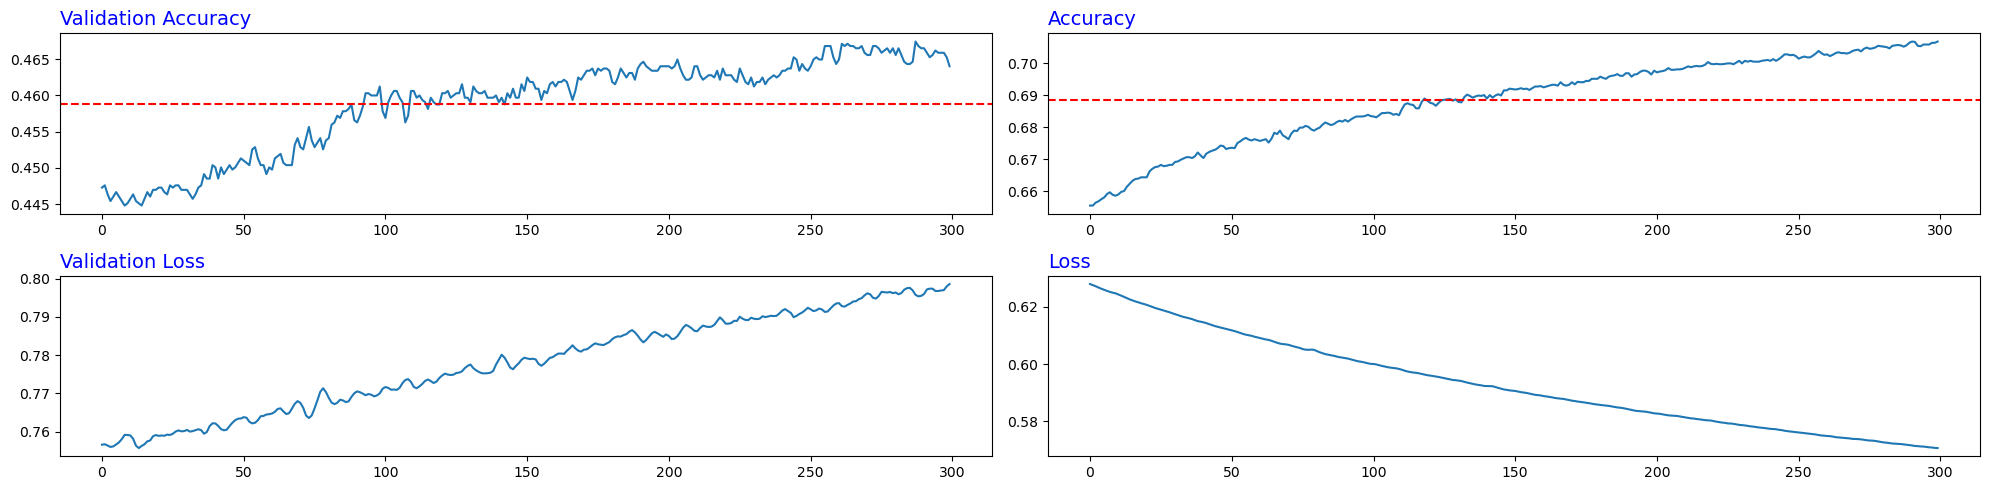

In [39]:
SMOOTHED = False
fig, ax = plt.subplots(2, 2, figsize=(20, 5))
i = 1000

# Apply rolling mean for smoother visualization
window_size = 0
if SMOOTHED:
    val_accuracy_smoothed = pd.Series(history.history['val_accuracy']).rolling(window=window_size).mean()
    accuracy_smoothed = pd.Series(history.history['accuracy']).rolling(window=window_size).mean()
    val_loss_smoothed = pd.Series(history.history['val_loss']).rolling(window=window_size).mean()
    loss_smoothed = pd.Series(history.history['loss']).rolling(window=window_size).mean()
else:
    val_accuracy_smoothed = pd.Series(history.history['val_accuracy']).loc[:i]
    accuracy_smoothed = pd.Series(history.history['accuracy']).loc[:i]
    val_loss_smoothed = pd.Series(history.history['val_loss']).loc[:i]
    loss_smoothed = pd.Series(history.history['loss']).loc[:i]

ax[0, 0].plot(val_accuracy_smoothed, label='Smoothed')
ax[0, 0].axhline(np.array(history.history['val_accuracy'][:]).mean(), color='red', linestyle='--')
ax[0, 0].set_title('Validation Accuracy', fontsize=14, color='blue', loc='left')

ax[0, 1].plot(accuracy_smoothed, label='Smoothed')
ax[0, 1].axhline(np.array(history.history['accuracy'][:]).mean(), color='red', linestyle='--')
ax[0, 1].set_title('Accuracy', fontsize=14, color='blue', loc='left')

ax[1, 0].plot(val_loss_smoothed, label='Smoothed')
ax[1, 0].set_title('Validation Loss', fontsize=14, color='blue', loc='left')

ax[1, 1].plot(loss_smoothed, label='Smoothed')
ax[1, 1].set_title('Loss', fontsize=14, color='blue', loc='left')

plt.tight_layout()

## KFOLD cross validation

In [61]:
USE_CBRA = True
USE_OTKA = True
TASK = 'hypno'  #'gender' or 'age', 'hypno'
DOWN_SAMPLE = True

if USE_CBRA:
    if USE_OTKA:
        # First we need to create a balance data (exactly the same data that we used in the above classifier with the exact same index)
        idx_int = [int(i) - 1 for i in sub_ids]
        cbramod_dict = torch.load('data/benchmarking/CBraMod_features_gender_seg-4s.pt', weights_only=False)
        X_e_sub_52 = torch.load('data/benchmarking/CBraMod_features_sub_52_seg-4s.pt', weights_only=False)
        X_e = np.asarray(cbramod_dict['features'])
        seg_per_sub = X_e.shape[0] // 51
        X_e = X_e.reshape(51, seg_per_sub, -1)
        X_e_sub_52 = np.concatenate([X_e_sub_52[None], np.full((1, *X_e_sub_52.shape), np.nan)], axis=1) # reshape to (1, 416, 3200) with NaNs for missing part
        X_e = np.concatenate([X_e, X_e_sub_52])

        if TASK == 'hypno':
            classes = behavioral[['hypnotizability_total', 'bids_id']].dropna().set_index('bids_id')
            classes['hypnotizability_total'] = classes['hypnotizability_total'].apply(lambda x: 1 if x > 5 else 0)

            if DOWN_SAMPLE:
                n_min = classes['hypnotizability_total'].value_counts().min()

                y0_sub_ids = classes.query("hypnotizability_total == 0").index[:n_min]
                y1_sub_ids = classes.query("hypnotizability_total == 1").index[:n_min]

                selected_sub_ids = y1_sub_ids.append(y0_sub_ids)
            else:
                selected_sub_ids = classes.index

            selected_idx = selected_sub_ids.to_numpy(dtype=int) - 1

            X_e = X_e[selected_idx]
            subject_y = classes.loc[selected_sub_ids, 'hypnotizability_total'].to_numpy().astype(int)
            subject_groups = selected_sub_ids.to_numpy(dtype=int)

            feats = X_e.reshape(-1, X_e.shape[-1])
            y = np.repeat(subject_y, seg_per_sub)
            groups = np.repeat(subject_groups, seg_per_sub)

            # Remove missing CBraMod segments, e.g. missing sub-52 sessions.
            valid = ~np.isnan(feats).any(axis=1)
            feats = feats[valid]
            y = y[valid]
            groups = groups[valid]
        
        if TASK == 'gender':
            X_e = X_e[idx_int]
            y = np.asarray(cbramod_dict['gender'])
            y = np.concatenate([np.asarray(cbramod_dict['gender']), np.array([1])]) # last subject gender
            y = np.where(y == 0, 1, 0)
            y = y[idx_int]
            y = np.repeat(y, seg_per_sub)  # X_e.shape[0]//52 = 832
            groups = np.asarray(cbramod_dict['subject_ids'])
            groups = np.concatenate([groups, np.array([52])])  # last subject id
            groups = groups[idx_int]
            groups = np.repeat(groups, seg_per_sub)

        # remove NaNs
        to_be_rm = seg_per_sub//2
        X_e = X_e.reshape(-1, X_e.shape[-1])[:-to_be_rm]
        y = y[:-to_be_rm]
        groups = groups[:-to_be_rm]

        feats = X_e

    else:
        cbramod_dict = torch.load('data/benchmarking/ds005385_extracted_CBraMod_features_seg-4s.pt', weights_only=False)
        feats = np.asarray(cbramod_dict['features'])
        subject_y = np.asarray(cbramod_dict[TASK])
        subject_ids_cbra = np.asarray(cbramod_dict['subject_ids']).astype(str)
        needs_group_downsample = True

        if feats.shape[0] % subject_y.shape[0] != 0:
            raise ValueError('CBraMod features cannot be evenly grouped by subject.')

        n_rep = int(feats.shape[0] / subject_y.shape[0])
        feats_by_subject = feats.reshape(subject_y.shape[0], n_rep, -1)

        if 'sub_ids' in globals():
            selected_sub_ids = np.asarray(sub_ids).astype(str)
            missing_in_cbra = sorted(set(selected_sub_ids) - set(subject_ids_cbra))
            extra_in_cbra = sorted(set(subject_ids_cbra) - set(selected_sub_ids))

            print('Subject alignment check:')
            print(f'  Raw branch subjects: {len(selected_sub_ids)}')
            print(f'  CBraMod subjects available: {len(subject_ids_cbra)}')
            print(f'  Missing in CBraMod: {len(missing_in_cbra)}')
            if missing_in_cbra:
                print(f'    Example missing subjects: {missing_in_cbra[:10]}')
            print(f'  Extra CBraMod subjects not used here: {len(extra_in_cbra)}')

            if missing_in_cbra:
                raise ValueError('CBraMod is missing subjects selected in the raw branch.')

            subject_index = {sub_id: idx for idx, sub_id in enumerate(subject_ids_cbra)}
            aligned_idx = np.array([subject_index[sub_id] for sub_id in selected_sub_ids])
            aligned_subject_ids = subject_ids_cbra[aligned_idx]
            aligned_subject_y = subject_y[aligned_idx]

            feats = feats_by_subject[aligned_idx].reshape(-1, feats_by_subject.shape[-1])
            y = aligned_subject_y.repeat(n_rep)
            groups = np.repeat(aligned_subject_ids, n_rep)
            needs_group_downsample = False

            print(f'  Exact subject order match: {np.array_equal(aligned_subject_ids, selected_sub_ids)}')
            print(f'  Segments per subject: {n_rep}')
            print(f'  Total CBraMod samples after alignment: {len(y)}')
            print(f'  Class distribution after alignment: {np.bincount(y)}')
            print(f'  Unique groups after alignment: {len(np.unique(groups))}')
        else:
            print('sub_ids not found in the notebook state. Falling back to CBraMod-only group balancing.')
            y = subject_y.repeat(n_rep)
            groups = np.repeat(subject_ids_cbra, n_rep)

        if DOWN_SAMPLE and needs_group_downsample:
            # Downsample to balance classes while keeping group structure intact
            print("Before downsampling:")
            print(f"  Class distribution: {np.bincount(y)}")
            print(f"  Total samples: {len(y)}")

            # Map each unique group to its class
            group_to_class = {}
            for idx, group_id in enumerate(groups):
                if group_id not in group_to_class:
                    group_to_class[group_id] = y[idx]

            # Separate groups by class
            class_0_groups = np.array([g for g, c in group_to_class.items() if c == 0])
            class_1_groups = np.array([g for g, c in group_to_class.items() if c == 1])

            # Downsample to match minority class
            n_minority = min(len(class_0_groups), len(class_1_groups))
            selected_groups = np.concatenate([
                np.random.choice(class_0_groups, n_minority, replace=False),
                np.random.choice(class_1_groups, n_minority, replace=False)
            ])

            # Create mask for selected groups
            mask = np.isin(groups, selected_groups)
            feats = feats[mask]
            y = y[mask]
            groups = groups[mask]

            print("\nAfter downsampling:")
            print(f"  Class distribution: {np.bincount(y)}")
            print(f"  Total samples: {len(y)}")
            print(f"  Unique groups: {len(np.unique(groups))}")

In [58]:
os.environ['PYTHONHASHSEED'] = '0'
np.random.seed(42)
torch.manual_seed(42)
torch.mps.manual_seed(42)
keras.utils.set_random_seed(42)

sgkf = StratifiedGroupKFold(n_splits=5, random_state=None).split(feats, y, groups=groups)
scale = True

# Comprehensive history storage
fold_summaries = []  # Store fold-level summary stats
all_fold_histories = {}  # Store complete epoch-by-epoch history per fold

for folds, (train_idx, val_idx) in enumerate(sgkf):
    # Class balance information
    train_class_mean = y[train_idx].mean()
    val_class_mean = y[val_idx].mean()
    train_size = len(train_idx)
    val_size = len(val_idx)
    
    print(f"Fold {folds}: Train class balance={train_class_mean:.4f}, Val class balance={val_class_mean:.4f}")

    if scale:
        scaler = StandardScaler().fit(feats)
        feats_train = scaler.transform(feats[train_idx])
        feats_val = scaler.transform(feats[val_idx])
    else:
        feats_train = feats[train_idx]
        feats_val = feats[val_idx]

    cls_model = keras.models.Sequential([
        layers.Dense(1, activation='sigmoid')
    ])

    cls_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss=keras.losses.BinaryCrossentropy(from_logits=False),
        metrics=[
            keras.metrics.AUC(name="auc"),
            keras.metrics.BinaryAccuracy(threshold=0.5, name="accuracy")
        ]
    )

    callback = keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=50,
        restore_best_weights=True
    )

    cw = compute_class_weight(
        class_weight='balanced',
        classes=np.unique(y[train_idx]),
        y=y[train_idx]
    )
    
    class_weights = dict(zip(np.unique(y[train_idx]), cw))

    history = cls_model.fit(
        feats_train, y[train_idx],
        epochs=300,
        batch_size=2048,
        validation_data=(feats_val, y[val_idx]),
        class_weight=class_weights,
        callbacks=callback,
        shuffle=True,
        verbose=0
    )

    # Store complete epoch-by-epoch history
    all_fold_histories[folds] = history.history
    
    # Store fold summary (best metrics and class balance)
    fold_summary = {
        'fold': folds,
        'train_class_balance': train_class_mean,
        'val_class_balance': val_class_mean,
        'train_size': train_size,
        'val_size': val_size,
        'best_epoch': np.argmax(history.history['val_accuracy']),
        'best_val_accuracy': np.max(history.history['val_accuracy']),
        'best_val_auc': np.max(history.history['val_auc']),
        'best_val_loss': np.min(history.history['val_loss']),
        'final_train_accuracy': history.history['accuracy'][-1],
        'final_train_auc': history.history['auc'][-1],
        'final_train_loss': history.history['loss'][-1],
        'num_epochs_trained': len(history.history['loss'])
    }
    fold_summaries.append(fold_summary)

# Create summary DataFrame
fold_summary_df = pd.DataFrame(fold_summaries)
print("\n" + "="*80)
print("K-FOLD CROSS-VALIDATION SUMMARY")
print("="*80)
print(fold_summary_df.to_string(index=False))
print("\nOverall Results:")
print(f"  Mean Val Accuracy: {fold_summary_df['best_val_accuracy'].mean():.4f} ± {fold_summary_df['best_val_accuracy'].std():.4f}")
print(f"  Mean Val AUC:      {fold_summary_df['best_val_auc'].mean():.4f} ± {fold_summary_df['best_val_auc'].std():.4f}")
print(f"  Mean Val Loss:     {fold_summary_df['best_val_loss'].mean():.4f} ± {fold_summary_df['best_val_loss'].std():.4f}")

Fold 0: Train class balance=0.5970, Val class balance=0.6667
Fold 1: Train class balance=0.6176, Val class balance=0.5882
Fold 2: Train class balance=0.6087, Val class balance=0.6250
Fold 3: Train class balance=0.6269, Val class balance=0.5556
Fold 4: Train class balance=0.6087, Val class balance=0.6250

K-FOLD CROSS-VALIDATION SUMMARY
 fold  train_class_balance  val_class_balance  train_size  val_size  best_epoch  best_val_accuracy  best_val_auc  best_val_loss  final_train_accuracy  final_train_auc  final_train_loss  num_epochs_trained
    0             0.597015           0.666667       13936      3744         213           0.468216      0.492943       0.959329              0.913964         0.972189          0.237846                 264
    1             0.617647           0.588235       14144      3536           0           0.511029      0.534259       0.844581              0.877262         0.948682          0.305410                  51
    2             0.608696           0.625000  

In [23]:
# Save comprehensive results to files - BEST PRACTICES
import pickle
import json
from datetime import datetime

# Create output directory
output_dir = f'logs/{TASK}_classifier_kfold_{datetime.now().strftime("%Y%m%d_%H%M%S")}'
os.makedirs(output_dir, exist_ok=True)

print("="*80)
print("SAVING K-FOLD CROSS-VALIDATION RESULTS")
print("="*80)

# 1. Save fold_summary_df - BEST: Parquet (preserves types + compression)
#    Alternative 1: CSV (human readable, works everywhere)
#    Alternative 2: HDF5 (good for large data)

# fold_summary_df.to_parquet(f'{output_dir}/fold_summary.parquet', index=False)
# print(f"✓ Saved fold summary (Parquet): {output_dir}/fold_summary.parquet")

fold_summary_df.to_csv(f'{output_dir}/fold_summary.csv', index=False)
print(f"✓ Saved fold summary (CSV): {output_dir}/fold_summary.csv")

# 2. Save all_fold_histories - BEST: Both pickle + JSON
#    Pickle: Complete, preserves all Python objects, fast
#    JSON: Portable, human-readable, loadable in other languages

# Option A: Pickle (RECOMMENDED - preserves exact structure)
with open(f'{output_dir}/all_fold_histories.pkl', 'wb') as f:
    pickle.dump(all_fold_histories, f)
print(f"✓ Saved fold histories (Pickle): {output_dir}/all_fold_histories.pkl")

# Option B: JSON (portable alternative - converts to standard types)
def convert_to_serializable(obj):
    """Convert numpy/torch types to JSON-serializable types"""
    if isinstance(obj, dict):
        return {k: convert_to_serializable(v) for k, v in obj.items()}
    elif isinstance(obj, list):
        return [convert_to_serializable(v) for v in obj]
    elif hasattr(obj, 'tolist'):  # numpy arrays, torch tensors
        return obj.tolist()
    elif isinstance(obj, (int, float, str, bool, type(None))):
        return obj
    else:
        return str(obj)

all_fold_histories_json = convert_to_serializable(all_fold_histories)
with open(f'{output_dir}/all_fold_histories.json', 'w') as f:
    json.dump(all_fold_histories_json, f, indent=2)
print(f"✓ Saved fold histories (JSON): {output_dir}/all_fold_histories.json")

# 3. Create detailed metrics table (one row per epoch per fold)
detailed_metrics = []
for fold_id, history in all_fold_histories.items():
    fold_data = fold_summary_df[fold_summary_df['fold'] == fold_id].iloc[0]
    for epoch in range(len(history['loss'])):
        detailed_metrics.append({
            'fold': fold_id,
            'train_class_balance': fold_data['train_class_balance'],
            'val_class_balance': fold_data['val_class_balance'],
            'epoch': epoch + 1,
            'train_loss': history['loss'][epoch],
            'train_accuracy': history['accuracy'][epoch],
            'train_auc': history['auc'][epoch],
            'val_loss': history['val_loss'][epoch],
            'val_accuracy': history['val_accuracy'][epoch],
            'val_auc': history['val_auc'][epoch],
        })

detailed_df = pd.DataFrame(detailed_metrics)
# detailed_df.to_parquet(f'{output_dir}/detailed_metrics_per_epoch.parquet', index=False)
detailed_df.to_csv(f'{output_dir}/detailed_metrics_per_epoch.csv', index=False)
# print(f"✓ Saved detailed metrics (Parquet): {output_dir}/detailed_metrics_per_epoch.parquet")
print(f"✓ Saved detailed metrics (CSV): {output_dir}/detailed_metrics_per_epoch.csv")

# 4. Save metadata about the results
metadata = {
    'task': TASK,
    'n_folds': len(fold_summaries),
    'timestamp': datetime.now().isoformat(),
    'mean_val_accuracy': float(fold_summary_df['best_val_accuracy'].mean()),
    'std_val_accuracy': float(fold_summary_df['best_val_accuracy'].std()),
    'mean_val_auc': float(fold_summary_df['best_val_auc'].mean()),
    'std_val_auc': float(fold_summary_df['best_val_auc'].std()),
}
with open(f'{output_dir}/metadata.json', 'w') as f:
    json.dump(metadata, f, indent=2)
print(f"✓ Saved metadata: {output_dir}/metadata.json")

print(f"\n✓ ALL RESULTS SAVED TO: {output_dir}")
print("\nFiles created:")
print("  - fold_summary.parquet (RECOMMENDED for fold-level metrics)")
print("  - fold_summary.csv (for viewing in Excel/spreadsheet)")
print("  - all_fold_histories.pkl (RECOMMENDED for loading in Python)")
print("  - all_fold_histories.json (portable format for other languages)")
print("  - detailed_metrics_per_epoch.parquet")
print("  - detailed_metrics_per_epoch.csv")
print("  - metadata.json")

SAVING K-FOLD CROSS-VALIDATION RESULTS
✓ Saved fold summary (CSV): logs/gender_classifier_kfold_20260422_165450/fold_summary.csv
✓ Saved fold histories (Pickle): logs/gender_classifier_kfold_20260422_165450/all_fold_histories.pkl
✓ Saved fold histories (JSON): logs/gender_classifier_kfold_20260422_165450/all_fold_histories.json
✓ Saved detailed metrics (CSV): logs/gender_classifier_kfold_20260422_165450/detailed_metrics_per_epoch.csv
✓ Saved metadata: logs/gender_classifier_kfold_20260422_165450/metadata.json

✓ ALL RESULTS SAVED TO: logs/gender_classifier_kfold_20260422_165450

Files created:
  - fold_summary.parquet (RECOMMENDED for fold-level metrics)
  - fold_summary.csv (for viewing in Excel/spreadsheet)
  - all_fold_histories.pkl (RECOMMENDED for loading in Python)
  - all_fold_histories.json (portable format for other languages)
  - detailed_metrics_per_epoch.parquet
  - detailed_metrics_per_epoch.csv
  - metadata.json


In [ ]:
# Load and visualize the saved results (run this in a new session)
import pickle
import json

# Example: modify this path to your results directory
# output_dir = 'logs/gender_classifier_kfold_20260422_120000'

# ============================================================================
# LOADING RESULTS - Choose the format that works best for your use case
# ============================================================================

# # OPTION 1: Load fold summary (choose one)
# fold_summary_df = pd.read_parquet(f'{output_dir}/fold_summary.parquet')  # Recommended
# fold_summary_df = pd.read_csv(f'{output_dir}/fold_summary.csv')

# # OPTION 2: Load detailed metrics per epoch (choose one)
# detailed_df = pd.read_parquet(f'{output_dir}/detailed_metrics_per_epoch.parquet')  # Recommended
# detailed_df = pd.read_csv(f'{output_dir}/detailed_metrics_per_epoch.csv')

# # OPTION 3: Load fold histories (choose one)
# # Pickle - Fastest, preserves exact structure, Python-only
# with open(f'{output_dir}/all_fold_histories.pkl', 'rb') as f:
#     all_fold_histories = pickle.load(f)

# # OR JSON - Portable to other languages, human-readable, slightly slower
# with open(f'{output_dir}/all_fold_histories.json', 'r') as f:
#     all_fold_histories = json.load(f)

# # OPTION 4: Load metadata
# with open(f'{output_dir}/metadata.json', 'r') as f:
#     metadata = json.load(f)

# ============================================================================
# PLOTTING EXAMPLES
# ============================================================================

# # Plot 1: Learning curves per fold
# fig, axes = plt.subplots(2, 3, figsize=(18, 8))
# for fold_id in detailed_df['fold'].unique():
#     fold_data = detailed_df[detailed_df['fold'] == fold_id]
#     row, col = divmod(fold_id, 3)
#     axes[row, col].plot(fold_data['epoch'], fold_data['val_accuracy'], label='Val Acc', linewidth=2)
#     axes[row, col].plot(fold_data['epoch'], fold_data['train_accuracy'], label='Train Acc', linewidth=2, alpha=0.7)
#     train_bal = fold_summary_df.loc[fold_id, 'train_class_balance']
#     val_bal = fold_summary_df.loc[fold_id, 'val_class_balance']
#     axes[row, col].set_title(f"Fold {fold_id} (Train: {train_bal:.3f}, Val: {val_bal:.3f})")
#     axes[row, col].set_ylabel('Accuracy')
#     axes[row, col].set_xlabel('Epoch')
#     axes[row, col].legend()
#     axes[row, col].grid(True, alpha=0.3)
# plt.tight_layout()

# # Plot 2: Comparison of class balance across folds
# fig, ax = plt.subplots(figsize=(10, 5))
# x = np.arange(len(fold_summary_df))
# ax.bar(x - 0.2, fold_summary_df['train_class_balance'], width=0.4, label='Train', alpha=0.8)
# ax.bar(x + 0.2, fold_summary_df['val_class_balance'], width=0.4, label='Val', alpha=0.8)
# ax.set_xlabel('Fold')
# ax.set_ylabel('Class Balance (positive class ratio)')
# ax.set_title('Class Balance Across Folds')
# ax.set_xticks(x)
# ax.legend()
# ax.grid(True, alpha=0.3, axis='y')

# # Plot 3: Best validation accuracy by fold
# fig, ax = plt.subplots(figsize=(10, 5))
# ax.bar(fold_summary_df['fold'], fold_summary_df['best_val_accuracy'], alpha=0.7, color='steelblue')
# ax.axhline(fold_summary_df['best_val_accuracy'].mean(), color='red', linestyle='--', 
#            label=f"Mean: {fold_summary_df['best_val_accuracy'].mean():.4f}")
# ax.set_xlabel('Fold')
# ax.set_ylabel('Best Validation Accuracy')
# ax.set_title('Best Validation Accuracy by Fold')
# ax.legend()
# ax.grid(True, alpha=0.3, axis='y')

In [ ]:
for i in range(40):   
    group_shuffle = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=i) # 8
    train_idx, val_idx = next(group_shuffle.split(X_input, y, groups=groups))
    print(i, y[train_idx].mean(), y[val_idx].mean())